In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd "/content/drive/MyDrive/College/GCI World/Final Assignment-20260513T165149Z-3-001/Final Assignment"

/content/drive/MyDrive/College/GCI World/Final Assignment-20260513T165149Z-3-001/Final Assignment


In [ ]:
from pathlib import Path
PATH=Path.cwd()
client_data=pd.read_csv(PATH/"telecom"/"Client.csv")
record_data=pd.read_csv(PATH/"telecom"/"Record.csv")

### Data Splitting
To ensure our analysis and models generalize well to unseen data, we will split the dataset into training and testing sets before proceeding with EDA.

In [ ]:
from sklearn.model_selection import train_test_split

# Splitting client_data
client_train, client_test = train_test_split(client_data, test_size=0.3, random_state=42)

# Splitting record_data
record_train, record_test = train_test_split(record_data, test_size=0.3, random_state=42)

print(f"Client Train Shape: {client_train.shape}, Test Shape: {client_test.shape}")
print(f"Record Train Shape: {record_train.shape}, Test Shape: {record_test.shape}")

Client Train Shape: (70000, 50), Test Shape: (30000, 50)
Record Train Shape: (70000, 51), Test Shape: (30000, 51)


In [ ]:
client_data.head()

,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,...,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays,Customer_ID
0,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,...,0.0,N,U,U,U,U,U,Y,361.0,1000001
1,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,...,0.0,Z,U,U,U,U,U,Y,240.0,1000002
2,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,...,0.0,N,U,Y,U,U,U,Y,1504.0,1000003
3,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,...,0.0,U,Y,U,U,U,U,Y,1812.0,1000004
4,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,...,0.0,I,U,U,U,U,U,Y,434.0,1000005


In [ ]:
record_data.head()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005


In [ ]:
print(f"client data shape={client_data.shape}")
print(f"record data shape={record_data.shape}")

client data shape=(100000, 50)
record data shape=(100000, 51)


In [ ]:
client_data.isnull().sum()

,0
uniqsubs,0
actvsubs,0
new_cell,0
crclscod,0
asl_flag,0
totcalls,0
totmou,0
totrev,0
adjrev,0
adjmou,0


In [ ]:
record_data.isnull().sum()

,0
rev_Mean,357
mou_Mean,357
totmrc_Mean,357
da_Mean,357
ovrmou_Mean,357
ovrrev_Mean,357
vceovr_Mean,357
datovr_Mean,357
roam_Mean,357
change_mou,891


### Imputing Missing Values in `client_data`
First, I will impute the missing numerical values in `client_data` with the median of each column.

### Imputing Missing Values in `record_data`
Next, I will impute the missing numerical values in `record_data` with the median of each column.

### Imputing Missing Values in Categorical Columns of `client_data`
Now, I will impute the remaining missing values in the categorical columns of `client_data` with their respective modes.

### Imputing Missing Values in Categorical Columns of `client_data`
Now, I will impute the remaining missing values in the categorical columns of `client_data` with their respective modes.

In [ ]:
client_data.isnull().sum()

,0
uniqsubs,0
actvsubs,0
new_cell,0
crclscod,0
asl_flag,0
totcalls,0
totmou,0
totrev,0
adjrev,0
adjmou,0


In [ ]:
record_data.isnull().sum()

,0
rev_Mean,357
mou_Mean,357
totmrc_Mean,357
da_Mean,357
ovrmou_Mean,357
ovrrev_Mean,357
vceovr_Mean,357
datovr_Mean,357
roam_Mean,357
change_mou,891


In [ ]:
client_data.describe()

,uniqsubs,actvsubs,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,...,models,truck,rv,lor,adults,income,numbcars,forgntvl,eqpdays,Customer_ID
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,99999.000000,98268.000000,98268.000000,69810.000000,76981.000000,74564.000000,50634.000000,98268.000000,99999.000000,1.000000e+05
mean,1.548140,1.358960,2877.141930,7648.363833,1031.924988,960.111528,7546.314699,2836.366920,57.913832,483.726493,...,1.545825,0.188820,0.082580,6.177238,2.530326,5.783112,1.567563,0.057974,391.932309,1.050000e+06
std,1.075255,0.655555,3790.863474,8666.558293,852.907511,840.170815,8594.889729,3756.513882,36.161292,438.485213,...,0.898395,0.391368,0.275248,4.735267,1.452819,2.182132,0.625456,0.233696,256.482193,2.886766e+04
min,1.000000,0.000000,0.000000,0.000000,3.650000,2.400000,0.000000,0.000000,0.480000,0.000000,...,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,-5.000000,1.000001e+06
25%,1.000000,1.000000,889.000000,2529.000000,518.980000,452.180000,2474.000000,868.000000,35.370000,176.140000,...,1.000000,0.000000,0.000000,2.000000,1.000000,4.000000,1.000000,0.000000,212.000000,1.025001e+06
50%,1.000000,1.000000,1822.000000,5191.500000,804.530000,737.760000,5102.500000,1789.000000,49.890000,360.190000,...,1.000000,0.000000,0.000000,5.000000,2.000000,6.000000,1.000000,0.000000,342.000000,1.050000e+06
75%,2.000000,2.000000,3492.000000,9776.000000,1263.767500,1188.175000,9661.000000,3442.000000,69.480000,655.670000,...,2.000000,0.000000,0.000000,9.000000,3.000000,7.000000,2.000000,0.000000,530.000000,1.075000e+06
max,196.000000,53.000000,98874.000000,233419.096700,27321.500000,27071.300000,232855.100000,98705.000000,924.270000,7040.130000,...,16.000000,1.000000,1.000000,15.000000,6.000000,9.000000,3.000000,1.000000,1823.000000,1.100000e+06


In [ ]:
record_data.describe()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
count,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99109.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05
mean,58.719985,513.559937,46.179136,0.888828,41.072247,13.559560,13.295062,0.261318,1.286405,-13.933818,...,165.280703,1.135804,10.044298,145.752225,109.666977,0.011700,1.782928,0.495620,18.833990,1.050000e+06
std,46.291677,525.168140,23.623489,2.177619,97.296150,30.500885,30.056089,3.126531,14.711374,276.087509,...,237.332918,17.768683,15.418406,159.348094,119.594305,0.547470,5.353953,0.499983,9.655794,2.886766e+04
min,-6.167500,0.000000,-26.915000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3875.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,1.000001e+06
25%,33.260000,150.750000,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-87.000000,...,18.536667,0.000000,1.666667,38.333333,28.666667,0.000000,0.000000,0.000000,11.000000,1.025001e+06
50%,48.195000,355.500000,44.990000,0.247500,2.750000,1.000000,0.682500,0.000000,0.000000,-6.250000,...,75.841667,0.000000,5.333333,101.000000,76.000000,0.000000,0.333333,0.000000,16.000000,1.050000e+06
75%,70.750000,703.000000,59.990000,0.990000,42.000000,14.437500,14.025000,0.000000,0.235000,63.000000,...,211.195000,0.000000,12.333333,199.666667,150.666667,0.000000,1.333333,1.000000,24.000000,1.075000e+06
max,3843.262500,12206.750000,409.990000,159.390000,4320.750000,1102.400000,896.087500,423.540000,3685.200000,31219.250000,...,4337.893333,2922.043333,489.666667,2289.000000,1894.333333,81.333333,212.666667,1.000000,61.000000,1.100000e+06


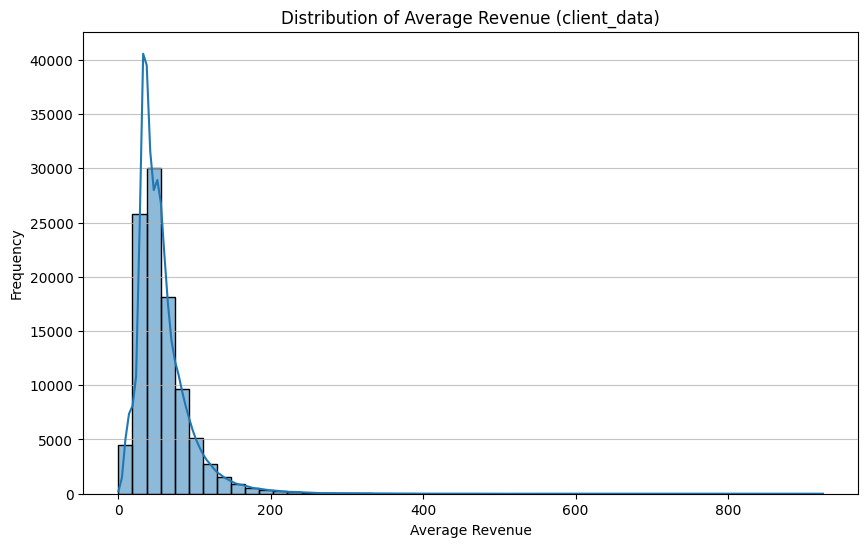

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(client_data['avgrev'], kde=True, bins=50)
plt.title('Distribution of Average Revenue (client_data)')
plt.xlabel('Average Revenue')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

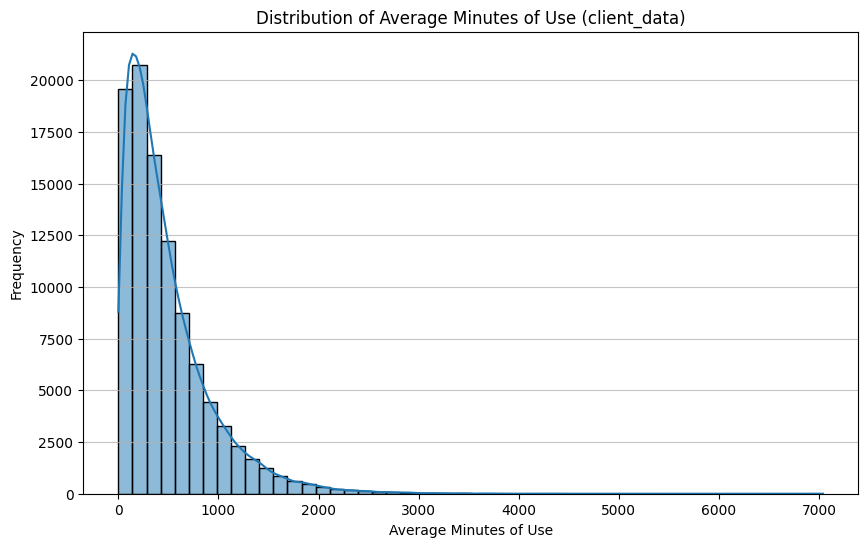

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(client_data['avgmou'], kde=True, bins=50)
plt.title('Distribution of Average Minutes of Use (client_data)')
plt.xlabel('Average Minutes of Use')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

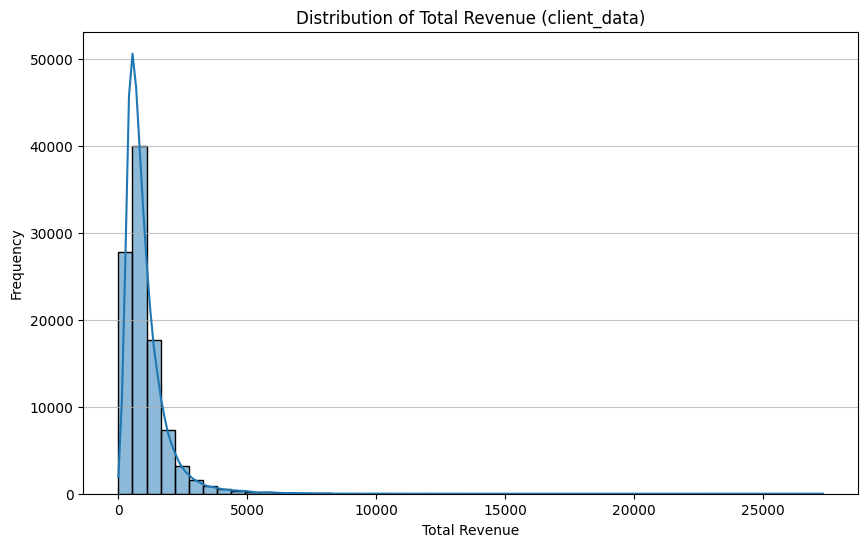

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(client_data['totrev'], kde=True, bins=50)
plt.title('Distribution of Total Revenue (client_data)')
plt.xlabel('Total Revenue')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

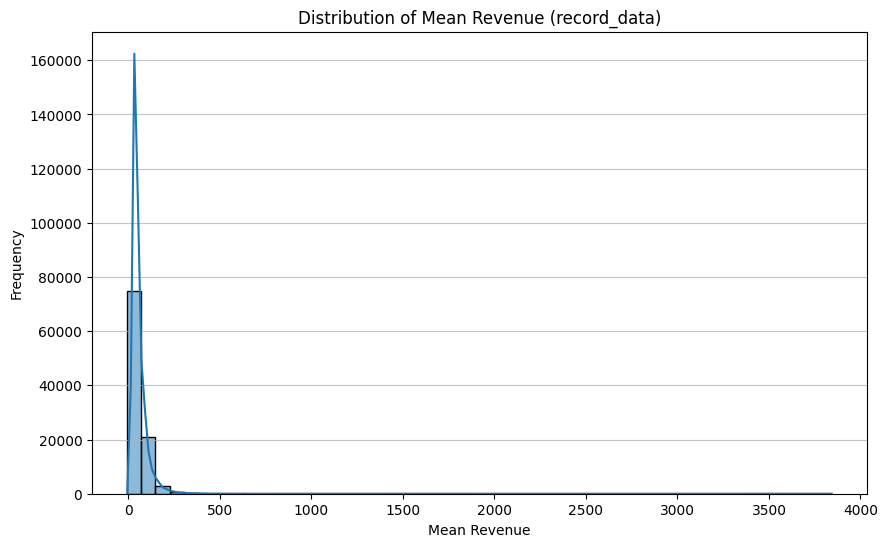

In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(record_data['rev_Mean'], kde=True, bins=50)
plt.title('Distribution of Mean Revenue (record_data)')
plt.xlabel('Mean Revenue')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.show()

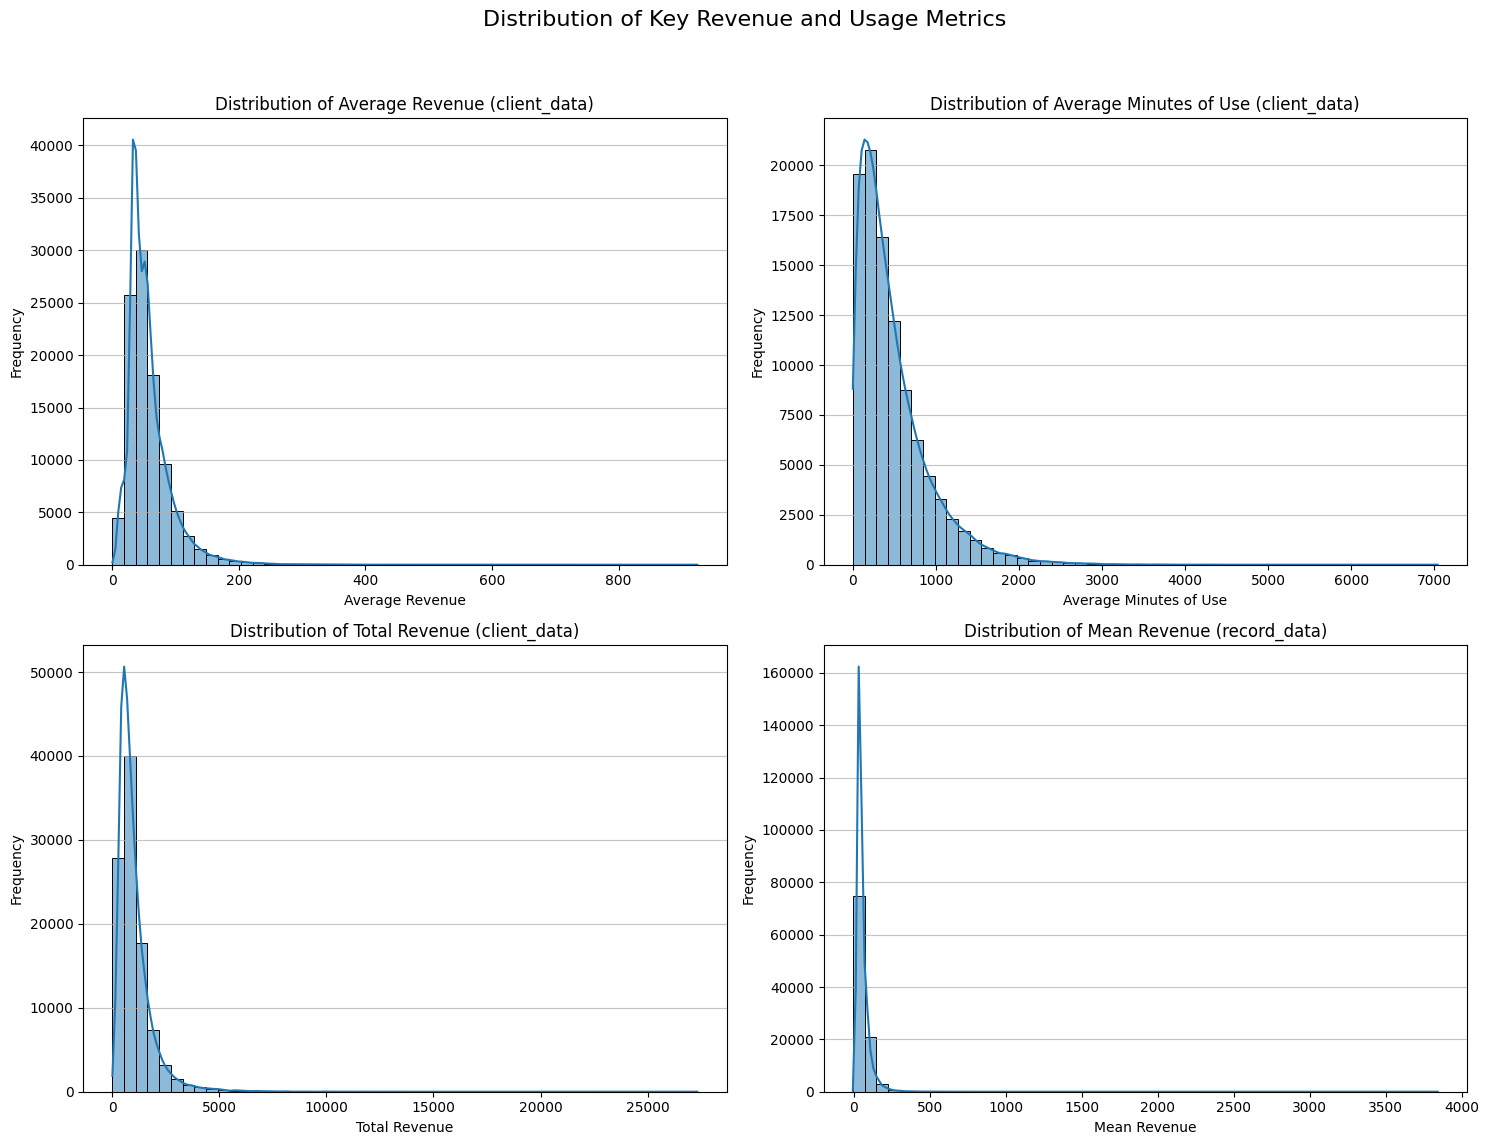

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle('Distribution of Key Revenue and Usage Metrics', fontsize=16)

# Plot 1: avgrev (client_data)
sns.histplot(client_data['avgrev'], kde=True, bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Distribution of Average Revenue (client_data)')
axes[0, 0].set_xlabel('Average Revenue')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].grid(axis='y', alpha=0.75)

# Plot 2: avgmou (client_data)
sns.histplot(client_data['avgmou'], kde=True, bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Distribution of Average Minutes of Use (client_data)')
axes[0, 1].set_xlabel('Average Minutes of Use')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].grid(axis='y', alpha=0.75)

# Plot 3: totrev (client_data)
sns.histplot(client_data['totrev'], kde=True, bins=50, ax=axes[1, 0])
axes[1, 0].set_title('Distribution of Total Revenue (client_data)')
axes[1, 0].set_xlabel('Total Revenue')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].grid(axis='y', alpha=0.75)

# Plot 4: rev_Mean (record_data)
sns.histplot(record_data['rev_Mean'], kde=True, bins=50, ax=axes[1, 1])
axes[1, 1].set_title('Distribution of Mean Revenue (record_data)')
axes[1, 1].set_xlabel('Mean Revenue')
axes[1, 1].set_ylabel('Frequency')
axes[1, 1].grid(axis='y', alpha=0.75)

# Adjust layout and display the plots
plt.tight_layout(rect=[0, 0.03, 1, 0.95]) # Adjust rect to prevent title overlap
plt.show()

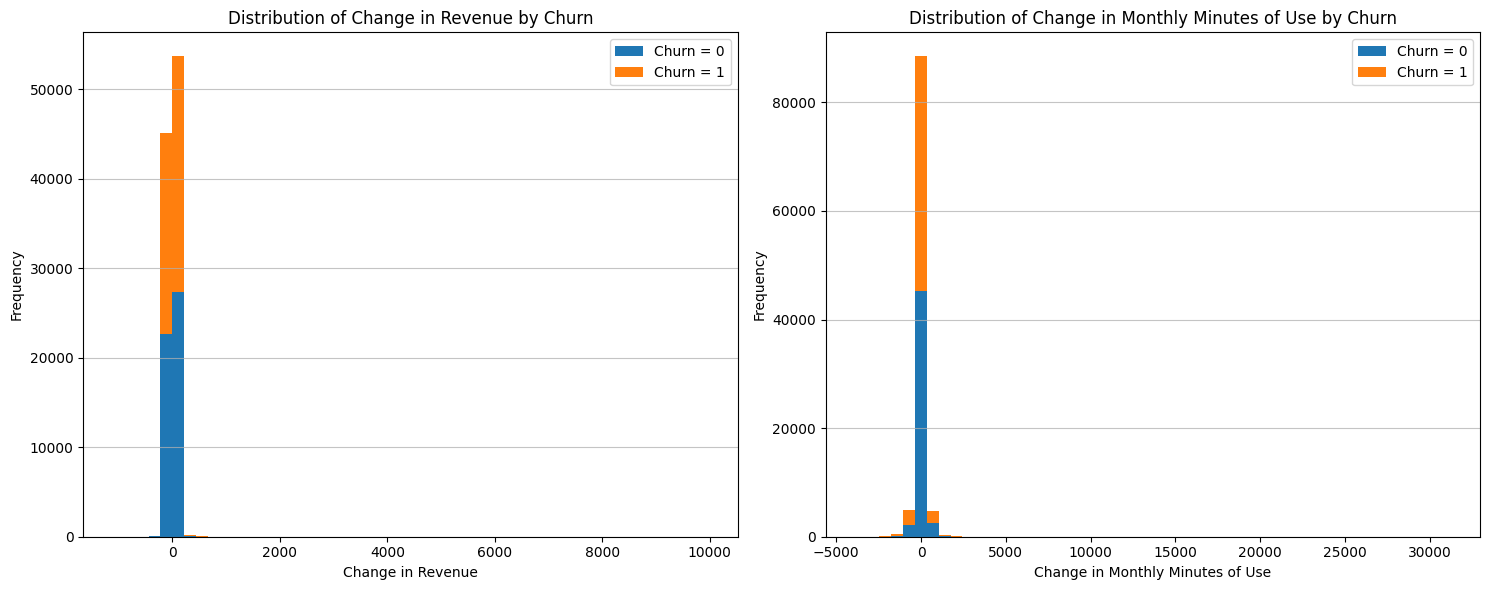

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Prepare data for stacked histogram
change_rev_churn_0 = record_data[record_data['churn'] == 0]['change_rev']
change_rev_churn_1 = record_data[record_data['churn'] == 1]['change_rev']

change_mou_churn_0 = record_data[record_data['churn'] == 0]['change_mou']
change_mou_churn_1 = record_data[record_data['churn'] == 1]['change_mou']

# Plot for change_rev against churn using matplotlib.pyplot.hist
axes[0].hist([change_rev_churn_0, change_rev_churn_1], bins=50, stacked=True, label=['Churn = 0', 'Churn = 1'])
axes[0].set_title('Distribution of Change in Revenue by Churn')
axes[0].set_xlabel('Change in Revenue')
axes[0].set_ylabel('Frequency')
axes[0].grid(axis='y', alpha=0.75)
axes[0].legend()

# Plot for change_mou against churn using matplotlib.pyplot.hist
axes[1].hist([change_mou_churn_0, change_mou_churn_1], bins=50, stacked=True, label=['Churn = 0', 'Churn = 1'])
axes[1].set_title('Distribution of Change in Monthly Minutes of Use by Churn')
axes[1].set_xlabel('Change in Monthly Minutes of Use')
axes[1].set_ylabel('Frequency')
axes[1].grid(axis='y', alpha=0.75)
axes[1].legend()

plt.tight_layout()
plt.show()

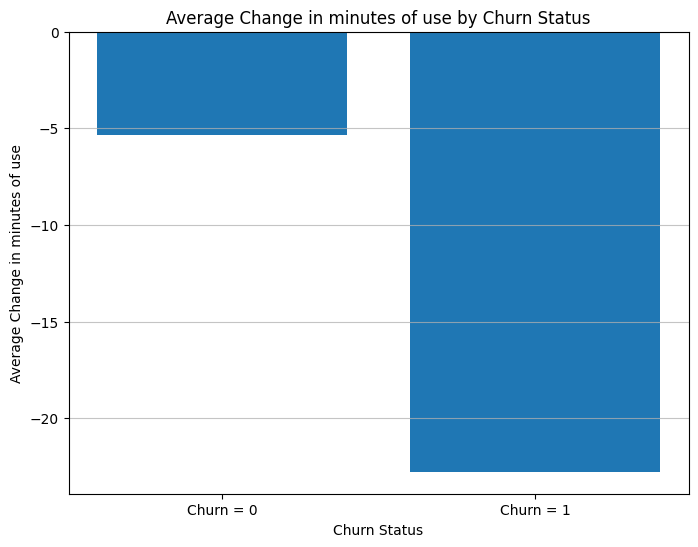

In [ ]:
import matplotlib.pyplot as plt

# Aggregate data: calculate the mean change_rev for each churn group
avg_change_rev_by_churn = record_data.groupby('churn')['change_mou'].mean()

# Create the bar plot
plt.figure(figsize=(8, 6))
plt.bar(x=avg_change_rev_by_churn.index, height=avg_change_rev_by_churn.values,
        tick_label=['Churn = 0', 'Churn = 1'])

plt.xlabel('Churn Status')
plt.ylabel('Average Change in minutes of use')
plt.title('Average Change in minutes of use by Churn Status')
plt.grid(axis='y', alpha=0.75)
plt.show()

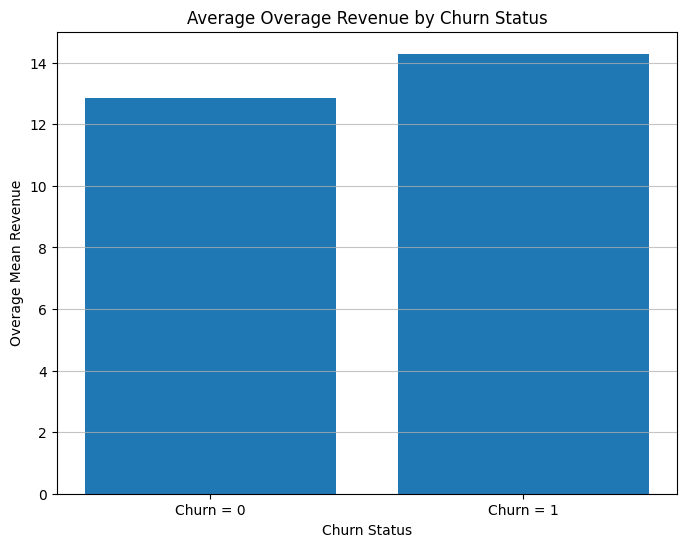

In [ ]:
import matplotlib.pyplot as plt

mean_overage_min = record_data.groupby('churn')['ovrrev_Mean'].mean()

plt.figure(figsize=(8, 6))
plt.bar(x=mean_overage_min.index, height=mean_overage_min.values,
        tick_label=['Churn = 0', 'Churn = 1'])
plt.xlabel('Churn Status')
plt.ylabel('Overage Mean Revenue')
plt.title('Average Overage Revenue by Churn Status')
plt.grid(axis='y', alpha=0.75)
plt.show()

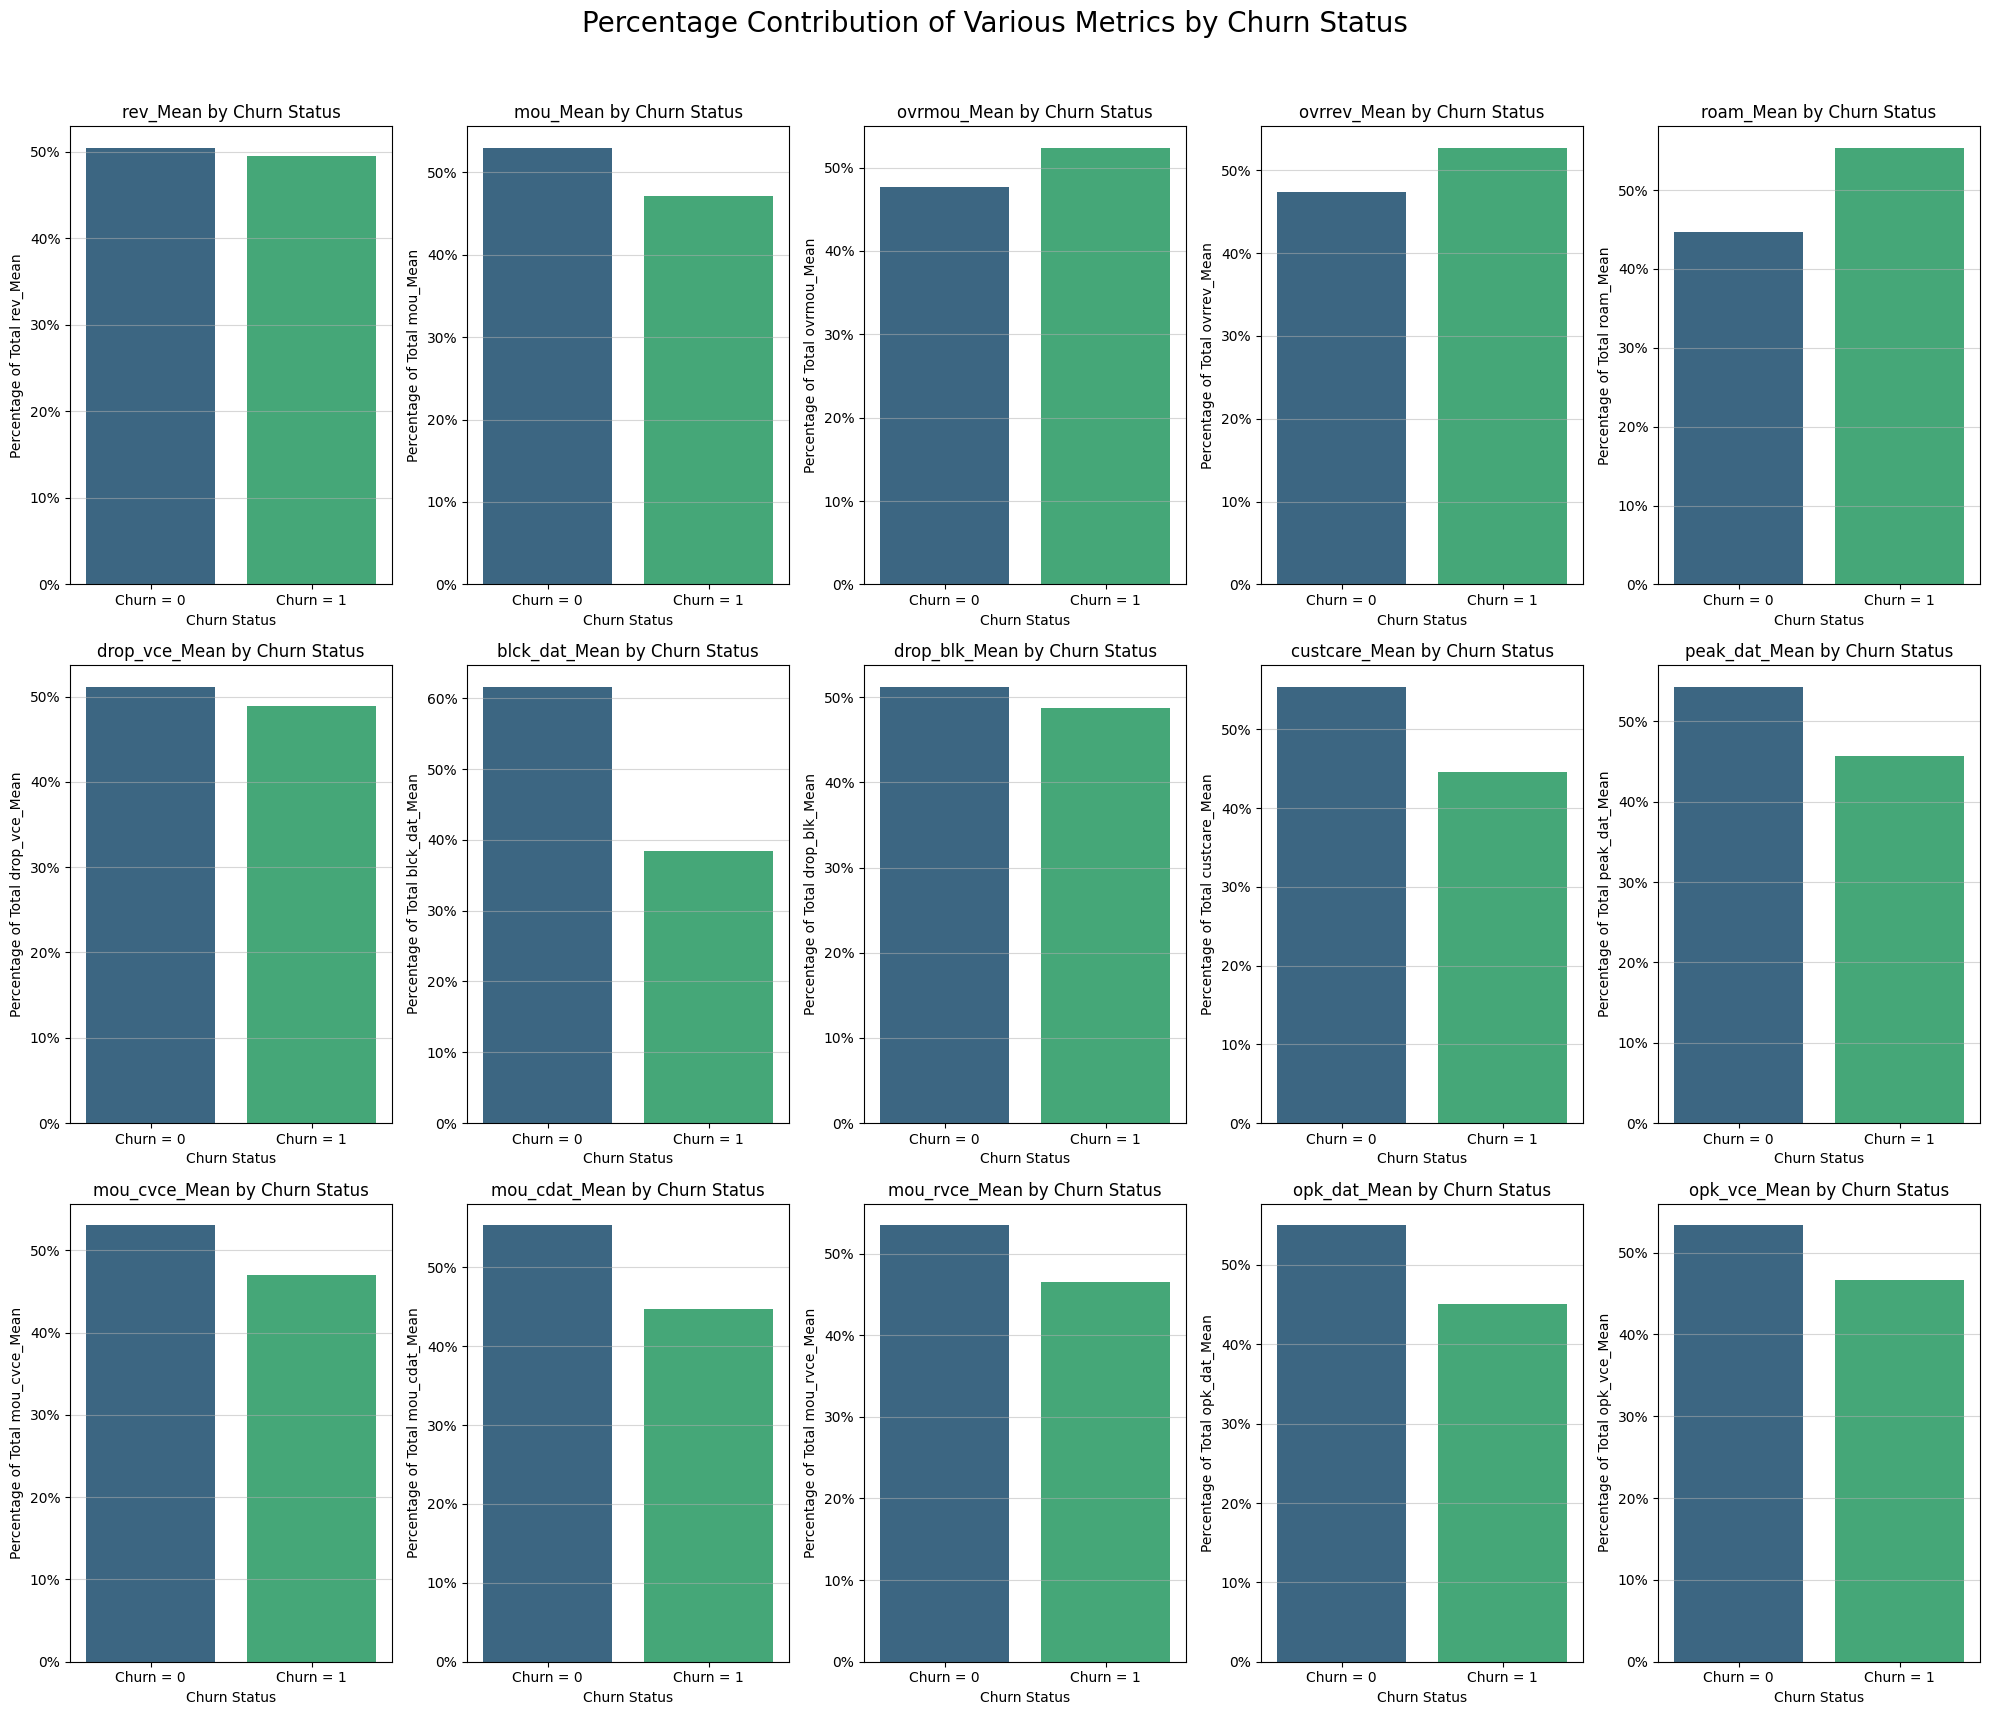

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # Import for percentage formatting

# Define the columns to plot
columns_to_plot = [
    'rev_Mean', 'mou_Mean', 'ovrmou_Mean', 'ovrrev_Mean', 'roam_Mean',
    'drop_vce_Mean', 'blck_dat_Mean', 'drop_blk_Mean', 'custcare_Mean','peak_dat_Mean',
    'mou_cvce_Mean','mou_cdat_Mean','mou_rvce_Mean','opk_dat_Mean','opk_vce_Mean'
]

# Create a 3x3 subplot grid
fig, axes = plt.subplots(3, 5, figsize=(20, 18))
fig.suptitle('Percentage Contribution of Various Metrics by Churn Status', fontsize=20) # Updated title
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

for i, col in enumerate(columns_to_plot):
    # Calculate the mean of the current column for each churn group
    mean_by_churn = record_data.groupby('churn')[col].mean()

    # Calculate percentages
    total_mean = mean_by_churn.sum()
    if total_mean == 0:
        # Handle cases where the sum is zero to avoid division by zero
        percentages = pd.Series([0.0, 0.0], index=[0, 1])
    else:
        percentages = (mean_by_churn / total_mean) * 100

    # Create a bar plot in the current subplot, addressing the FutureWarning
    sns.barplot(x=percentages.index, y=percentages.values, ax=axes[i], palette='viridis', hue=percentages.index, legend=False)
    axes[i].set_title(f'{col} by Churn Status') # Simplified subplot title
    axes[i].set_xlabel('Churn Status')
    axes[i].set_ylabel(f'Percentage of Total {col}') # Updated y-axis label
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Churn = 0', 'Churn = 1'])
    axes[i].grid(axis='y', alpha=0.5)

    # Format y-axis ticks as percentages
    formatter = mticker.PercentFormatter(xmax=100.0) # xmax=100.0 because the values are already percentages
    axes[i].yaxis.set_major_formatter(formatter)

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Adjust layout to prevent title overlap
plt.show()

In [ ]:
record_data.describe()

,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID
count,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99643.000000,99109.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05
mean,58.719985,513.559937,46.179136,0.888828,41.072247,13.559560,13.295062,0.261318,1.286405,-13.933818,...,165.280703,1.135804,10.044298,145.752225,109.666977,0.011700,1.782928,0.495620,18.833990,1.050000e+06
std,46.291677,525.168140,23.623489,2.177619,97.296150,30.500885,30.056089,3.126531,14.711374,276.087509,...,237.332918,17.768683,15.418406,159.348094,119.594305,0.547470,5.353953,0.499983,9.655794,2.886766e+04
min,-6.167500,0.000000,-26.915000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-3875.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,1.000001e+06
25%,33.260000,150.750000,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-87.000000,...,18.536667,0.000000,1.666667,38.333333,28.666667,0.000000,0.000000,0.000000,11.000000,1.025001e+06
50%,48.195000,355.500000,44.990000,0.247500,2.750000,1.000000,0.682500,0.000000,0.000000,-6.250000,...,75.841667,0.000000,5.333333,101.000000,76.000000,0.000000,0.333333,0.000000,16.000000,1.050000e+06
75%,70.750000,703.000000,59.990000,0.990000,42.000000,14.437500,14.025000,0.000000,0.235000,63.000000,...,211.195000,0.000000,12.333333,199.666667,150.666667,0.000000,1.333333,1.000000,24.000000,1.075000e+06
max,3843.262500,12206.750000,409.990000,159.390000,4320.750000,1102.400000,896.087500,423.540000,3685.200000,31219.250000,...,4337.893333,2922.043333,489.666667,2289.000000,1894.333333,81.333333,212.666667,1.000000,61.000000,1.100000e+06


In [ ]:
retain = record_data[record_data['churn'] == 0]['Customer_ID'].count()
left=record_data[record_data['churn'] == 1]['Customer_ID'].count()
retention_rate=(retain/(left+retain))*100
print(retention_rate)

50.438


The retention rate is 50.4 %

In [ ]:
for i, col in enumerate(columns_to_plot):
    # Calculate the mean of the current column for each churn group
    mean_by_churn = record_data.groupby('churn')[col].mean()

    # Calculate percentages
    total_mean = mean_by_churn.sum()
    if total_mean == 0:
        # Handle cases where the sum is zero to avoid division by zero
        percentages = pd.Series([0.0, 0.0], index=[0, 1])
        print(percentages)
    else:
        percentages = (mean_by_churn / total_mean) * 100
        print(percentages)

churn
0    50.42903
1    49.57097
Name: rev_Mean, dtype: float64
churn
0    52.917667
1    47.082333
Name: mou_Mean, dtype: float64
churn
0    47.665254
1    52.334746
Name: ovrmou_Mean, dtype: float64
churn
0    47.331694
1    52.668306
Name: ovrrev_Mean, dtype: float64
churn
0    44.674017
1    55.325983
Name: roam_Mean, dtype: float64
churn
0    51.147701
1    48.852299
Name: drop_vce_Mean, dtype: float64
churn
0    61.632327
1    38.367673
Name: blck_dat_Mean, dtype: float64
churn
0    51.216898
1    48.783102
Name: drop_blk_Mean, dtype: float64
churn
0    55.40637
1    44.59363
Name: custcare_Mean, dtype: float64
churn
0    54.305288
1    45.694712
Name: peak_dat_Mean, dtype: float64
churn
0    53.02238
1    46.97762
Name: mou_cvce_Mean, dtype: float64
churn
0    55.315628
1    44.684372
Name: mou_cdat_Mean, dtype: float64
churn
0    53.437123
1    46.562877
Name: mou_rvce_Mean, dtype: float64
churn
0    54.976895
1    45.023105
Name: opk_dat_Mean, dtype: float64
churn
0    53.318

In [ ]:
columns_to=['change_mou','datovr_Mean','blck_vce_Mean','blck_dat_Mean','change_rev']
for i, col in enumerate(columns_to):
    # Calculate the mean of the current column for each churn group
    mean_by_churn = record_data.groupby('churn')[col].mean()
    print(mean_by_churn)

churn
0    -5.344265
1   -22.759003
Name: change_mou, dtype: float64
churn
0    0.265309
1    0.257244
Name: datovr_Mean, dtype: float64
churn
0    4.118370
1    3.925776
Name: blck_vce_Mean, dtype: float64
churn
0    0.031709
1    0.019740
Name: blck_dat_Mean, dtype: float64
churn
0   -1.410195
1   -0.621263
Name: change_rev, dtype: float64


In [ ]:
# How much revenue lost per churner?
# Note: 'avgrev' and 'totrev' are in 'client_data', 'rev_Mean' and 'churn' are in 'record_data'.
# To analyze 'avgrev' and 'totrev' by 'churn', the dataframes 'client_data' and 'record_data' would need to be merged first.
record_data.groupby('churn')[['rev_Mean']].mean()

# High-value churners = biggest problem
# Using record_data as 'df' is undefined and 'rev_Mean'/'churn' are in record_data
record_data['value_segment'] = pd.qcut(record_data['rev_Mean'], q=3, labels=['low','mid','high'])
# The original code had a SyntaxError: 'normalize within segment' is not a valid argument.
# To normalize within each 'value_segment', we get the size, then group by the 'value_segment' level and divide by the sum of each group.
record_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100)

/tmp/ipykernel_995/3757014943.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  record_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100)
/tmp/ipykernel_995/3757014943.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  record_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100)


value_segment  value_segment  churn
low            low            0        48.596977
                              1        51.403023
mid            mid            0        51.434666
                              1        48.565334
high           high           0        51.487359
                              1        48.512641
dtype: float64

In [ ]:
record_data.groupby('churn')['months'].describe()

,count,mean,std,min,25%,50%,75%,max
churn,,,,,,,,
0,50438.0,18.633074,9.975607,6.0,11.0,16.0,24.0,61.0
1,49562.0,19.038457,9.314720,6.0,12.0,17.0,24.0,61.0


In [ ]:
churn_by_month = record_data.groupby('months')['churn'].value_counts(normalize=True).unstack()

# Calculate percentage of churn == 1
churn_percentage_by_month = churn_by_month[1] * 100

print("Percentage of users with churn == 1 by month:")
print(churn_percentage_by_month)

Percentage of users with churn == 1 by month:
months
6     38.378378
7     33.259691
8     30.954936
9     28.799803
10    40.273591
11    65.126417
12    61.859771
13    55.441515
14    53.031634
15    52.359844
16    51.027778
17    51.554922
18    50.993377
19    49.242619
20    52.169236
21    49.340073
22    50.079745
23    51.697488
24    51.481322
25    48.225334
26    49.351996
27    50.982475
28    52.103560
29    50.140371
30    52.307692
31    50.028588
32    53.098827
33    49.717514
34    48.588710
35    48.998459
36    46.691635
37    48.732084
38    47.424512
39    50.666667
40    47.761194
41    50.704225
42    47.407407
43    46.666667
44    45.783133
45    44.609665
46    47.272727
47    48.076923
48    47.747748
49    47.982063
50    46.987952
51    58.041958
52    47.747748
53    37.931034
54    41.463415
55    38.461538
56    35.897436
57    21.951220
58    40.000000
59     9.375000
60    20.000000
61    50.000000
Name: 1, dtype: float64


In [ ]:
bins = [6, 12, 17, 24,61]
labels = ['6-12 months', '12-17 months', '17-24 months','24-61months']
record_data['month_segment'] = pd.cut(record_data['months'], bins=bins, labels=labels, right=False)

# Calculate churn percentage for each new month segment
churn_by_month_segment = record_data.groupby('month_segment')['churn'].value_counts(normalize=True).unstack()

# Calculate percentage of churn == 1 for each segment
churn_percentage_by_segment = churn_by_month_segment[1] * 100

print("Percentage of users with churn == 1 by month segment:")
print(churn_percentage_by_segment)

Percentage of users with churn == 1 by month segment:
month_segment
6-12 months     43.332071
12-17 months    55.443370
17-24 months    50.679010
24-61months     49.552117
Name: 1, dtype: float64


/tmp/ipykernel_995/3229447484.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  churn_by_month_segment = record_data.groupby('month_segment')['churn'].value_counts(normalize=True).unstack()


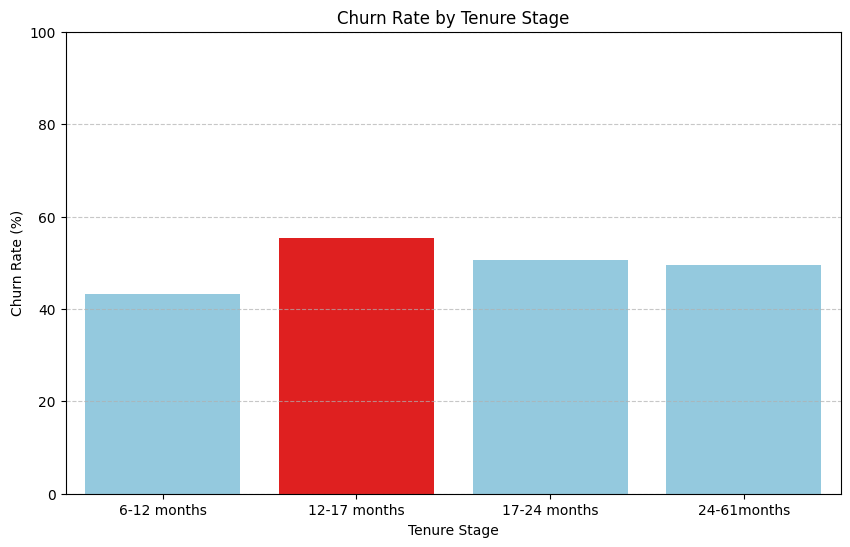

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a color list for the bars, highlighting '12-17 months' in red
colors = ['skyblue' if stage != '12-17 months' else 'red' for stage in churn_percentage_by_segment.index]

plt.figure(figsize=(10, 6))
sns.barplot(x=churn_percentage_by_segment.index, y=churn_percentage_by_segment.values, palette=colors, hue=churn_percentage_by_segment.index, legend=False)
plt.title('Churn Rate by Tenure Stage')
plt.xlabel('Tenure Stage')
plt.ylabel('Churn Rate (%)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.ylim(0, 100) # Set y-axis limit to 0-100 for percentage
plt.show()

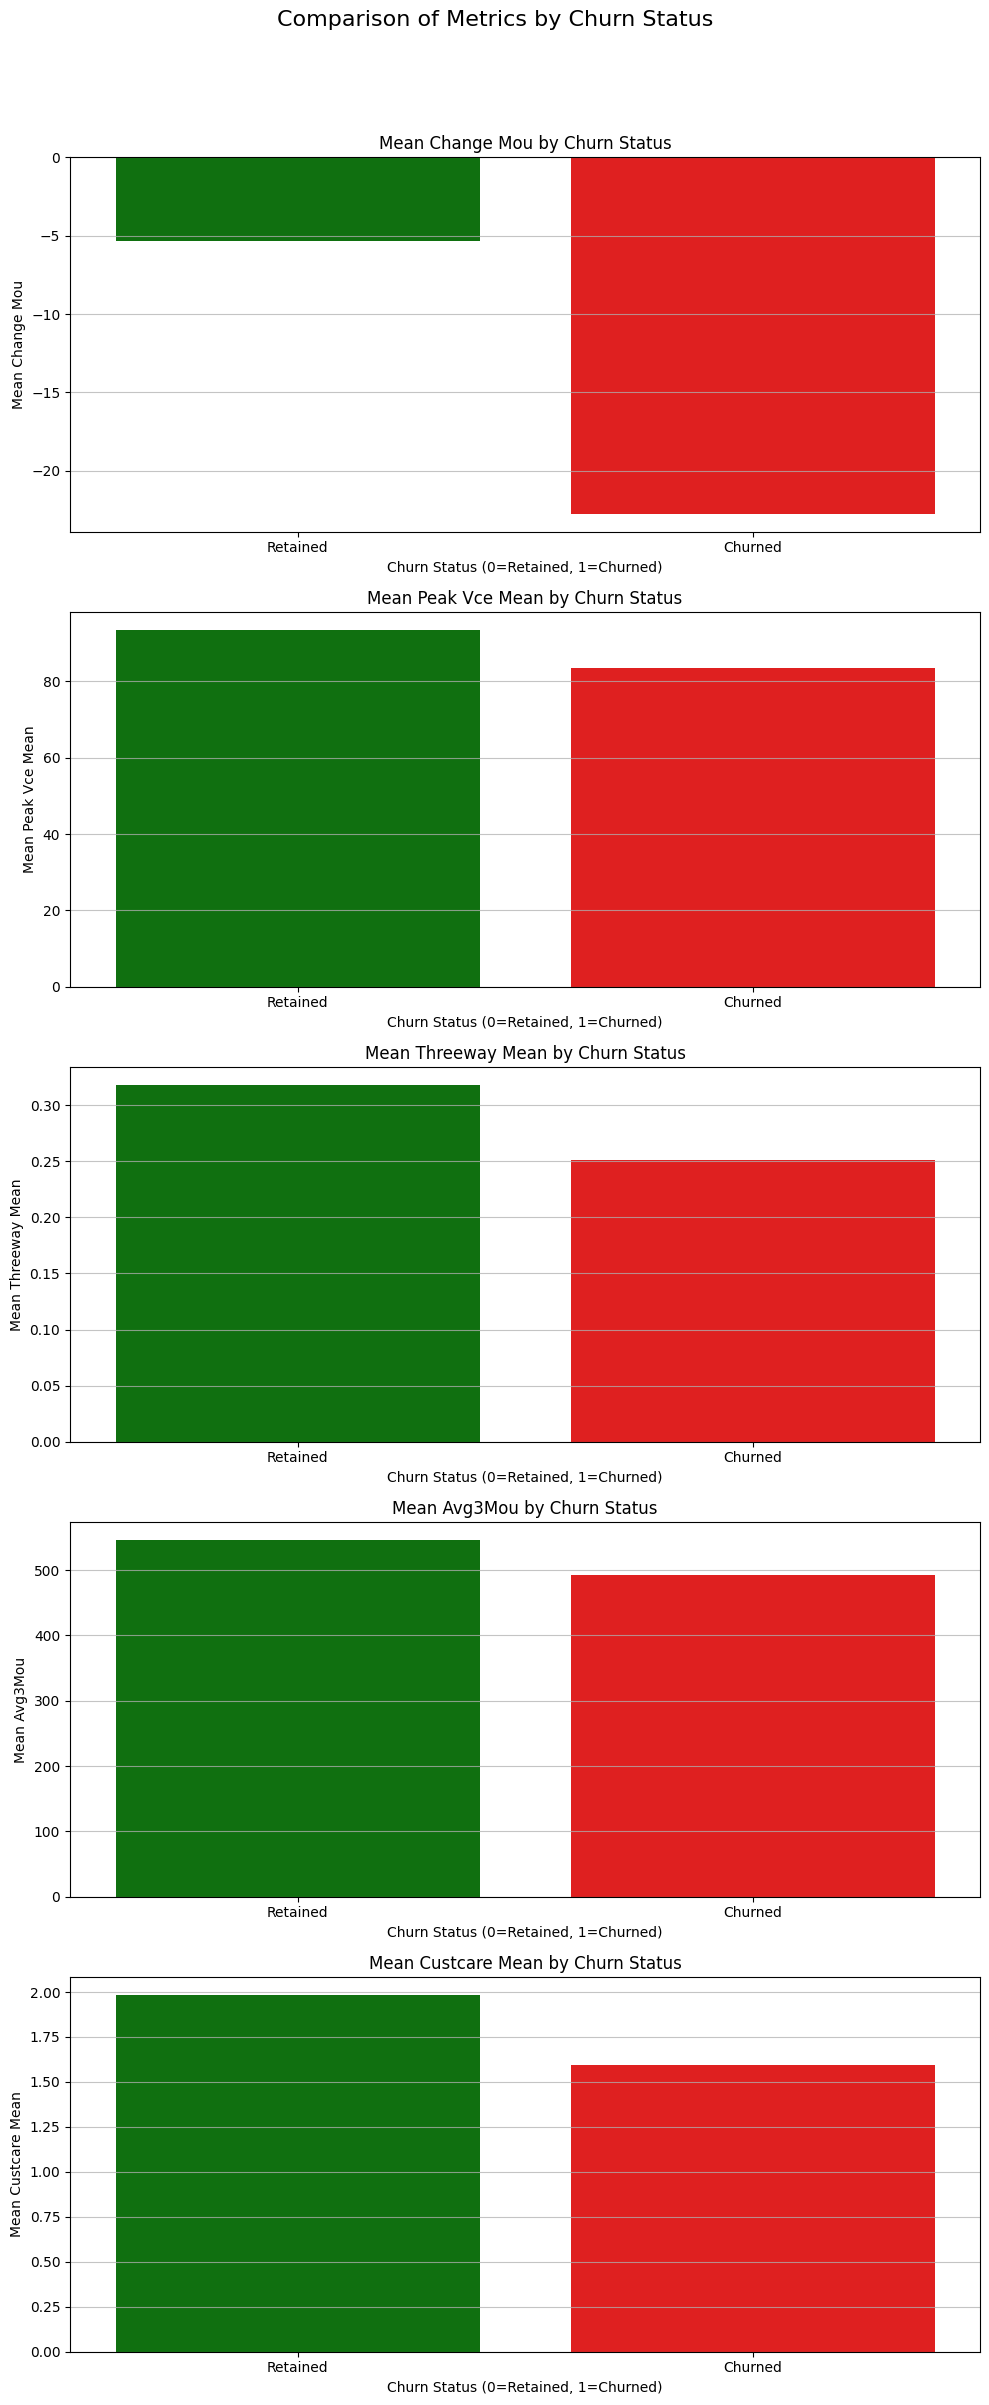

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Metrics to compare
metrics_to_compare = ['change_mou', 'peak_vce_Mean', 'threeway_Mean', 'avg3mou', 'custcare_Mean']

# Prepare data for plotting: mean of each metric grouped by churn status
churn_comparison = merged_data.groupby('churn')[metrics_to_compare].mean()

# Create subplots for each metric
fig, axes = plt.subplots(nrows=len(metrics_to_compare), ncols=1, figsize=(10, 5 * len(metrics_to_compare)))
fig.suptitle('Comparison of Metrics by Churn Status', fontsize=16, y=0.99)

for i, metric in enumerate(metrics_to_compare):
    sns.barplot(x=churn_comparison.index, y=churn_comparison[metric], ax=axes[i], palette=['green', 'red'], hue=churn_comparison.index, legend=False)
    axes[i].set_title(f'Mean {metric.replace("_", " ").title()} by Churn Status')
    axes[i].set_xlabel('Churn Status (0=Retained, 1=Churned)')
    axes[i].set_ylabel(f'Mean {metric.replace("_", " ").title()}')
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Retained', 'Churned'])
    axes[i].grid(axis='y', alpha=0.75)

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

In [ ]:
# Merge client_data and record_data on Customer_ID to combine relevant columns
merged_data = pd.merge(client_data, record_data, on='Customer_ID', how='inner')

# How much revenue lost per churner?
# Now that avgrev, totrev, and churn are in merged_data, we can group them.
print("Mean average and total revenue by churn status:")
print(merged_data.groupby('churn')[['avgrev','totrev']].mean())

# High-value churners = biggest problem
# Create 'value_segment' based on 'rev_Mean' (now in merged_data)
merged_data['value_segment'] = pd.qcut(merged_data['rev_Mean'], q=3, labels=['low','mid','high'])

# Normalize within each 'value_segment' for churn
print("\nPercentage of churn within each revenue value segment:")
print(merged_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100))

Mean average and total revenue by churn status:
          avgrev       totrev
churn                        
0      58.228573  1034.475849
1      57.593527  1029.329041

Percentage of churn within each revenue value segment:
value_segment  value_segment  churn
low            low            0        48.596977
                              1        51.403023
mid            mid            0        51.434666
                              1        48.565334
high           high           0        51.487359
                              1        48.512641
dtype: float64


/tmp/ipykernel_995/2260558360.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(merged_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100))
/tmp/ipykernel_995/2260558360.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(merged_data.groupby(['value_segment','churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100))


In [ ]:
# Users with overage AND high custcare = ticking time bombs
record_data['bill_shock_risk'] = ((record_data['ovrmou_Mean'] > 0) & (record_data['custcare_Mean'] > 2)).astype(int)
record_data.groupby('churn')['bill_shock_risk'].mean()
tot=record_data['bill_shock_risk'].sum()
record_data.groupby('churn')['bill_shock_risk'].sum()/tot*100

,bill_shock_risk
churn,
0,54.593825
1,45.406175


In [ ]:
record_data['bill_shock_risk'].head()

,bill_shock_risk
0,0
1,0
2,0
3,0
4,0


### Churned Customer Revenue Contribution by Tenure Stage

Let's examine the total revenue generated by churned customers, distinguishing between 'early stage' (first 12 months) and 'later stage' (after 12 months) of their tenure.

In [ ]:
# Define month stages: Early Stage (<=12 months), Later Stage (>12 months)
record_data['month_stage'] = record_data['months'].apply(lambda x: 'Early Stage' if x <= 12 else 'Later Stage')

# Filter for churned users
churned_customers = record_data[record_data['churn'] == 1]

# Group by month_stage and sum the 'rev_Mean' for churned customers
revenue_by_month_stage = churned_customers.groupby('month_stage')['rev_Mean'].sum()

# Calculate the total revenue from all churned customers
total_churned_revenue = churned_customers['rev_Mean'].sum()

# Calculate the percentage contribution of each month stage to total churned revenue
percentage_contribution = (revenue_by_month_stage / total_churned_revenue) * 100

print("Percentage contribution to total churned revenue by month stage:")
display(percentage_contribution)

Percentage contribution to total churned revenue by month stage:


,rev_Mean
month_stage,
Early Stage,31.716011
Later Stage,68.283989


### Percentage of Churned Customers by Tenure Stage

Let's determine the proportion of churned customers based on their tenure stage (early vs. later).

In [ ]:
# Calculate the count of churned customers in each month stage
churn_counts_by_stage = churned_customers.groupby('month_stage')['Customer_ID'].count()

# Calculate the total number of churned customers
total_churned_customers = churned_customers['Customer_ID'].count()

# Calculate the percentage of churned customers for each stage
percentage_churn_by_stage = (churn_counts_by_stage / total_churned_customers) * 100

print("Percentage of churned customers by month stage:")
display(percentage_churn_by_stage)

Percentage of churned customers by month stage:


,Customer_ID
month_stage,
Early Stage,30.620233
Later Stage,69.379767


### Call Outcome Analysis by Churn Status

Let's analyze the percentage of blocked, dropped, unanswered, and completed calls relative to the placed calls for both voice and data, segmented by churn status.

In [ ]:
# Calculate mean values for relevant call metrics by churn status
call_metrics_by_churn = record_data.groupby('churn')[[
    'blck_vce_Mean', 'drop_vce_Mean', 'unan_vce_Mean', 'plcd_vce_Mean', 'comp_vce_Mean',
    'blck_dat_Mean', 'drop_dat_Mean', 'unan_dat_Mean', 'plcd_dat_Mean', 'comp_dat_Mean'
]].mean()

# Initialize DataFrames to store percentages
voice_call_percentages = pd.DataFrame(index=[0, 1], columns=['Blocked_Vce_Pct', 'Dropped_Vce_Pct', 'Unanswered_Vce_Pct', 'Completed_Vce_Pct'])
data_call_percentages = pd.DataFrame(index=[0, 1], columns=['Blocked_Dat_Pct', 'Dropped_Dat_Pct', 'Unanswered_Dat_Pct', 'Completed_Dat_Pct'])

for churn_status in [0, 1]:
    # Voice Call Percentages
    placed_vce = call_metrics_by_churn.loc[churn_status, 'plcd_vce_Mean']
    if placed_vce > 0:
        voice_call_percentages.loc[churn_status, 'Blocked_Vce_Pct'] = (call_metrics_by_churn.loc[churn_status, 'blck_vce_Mean'] / placed_vce) * 100
        voice_call_percentages.loc[churn_status, 'Dropped_Vce_Pct'] = (call_metrics_by_churn.loc[churn_status, 'drop_vce_Mean'] / placed_vce) * 100
        voice_call_percentages.loc[churn_status, 'Unanswered_Vce_Pct'] = (call_metrics_by_churn.loc[churn_status, 'unan_vce_Mean'] / placed_vce) * 100
        voice_call_percentages.loc[churn_status, 'Completed_Vce_Pct'] = (call_metrics_by_churn.loc[churn_status, 'comp_vce_Mean'] / placed_vce) * 100
    else:
        voice_call_percentages.loc[churn_status, ['Blocked_Vce_Pct', 'Dropped_Vce_Pct', 'Unanswered_Vce_Pct', 'Completed_Vce_Pct']] = 0.0

    # Data Call Percentages
    placed_dat = call_metrics_by_churn.loc[churn_status, 'plcd_dat_Mean']
    if placed_dat > 0:
        data_call_percentages.loc[churn_status, 'Blocked_Dat_Pct'] = (call_metrics_by_churn.loc[churn_status, 'blck_dat_Mean'] / placed_dat) * 100
        data_call_percentages.loc[churn_status, 'Dropped_Dat_Pct'] = (call_metrics_by_churn.loc[churn_status, 'drop_dat_Mean'] / placed_dat) * 100
        data_call_percentages.loc[churn_status, 'Unanswered_Dat_Pct'] = (call_metrics_by_churn.loc[churn_status, 'unan_dat_Mean'] / placed_dat) * 100
        data_call_percentages.loc[churn_status, 'Completed_Dat_Pct'] = (call_metrics_by_churn.loc[churn_status, 'comp_dat_Mean'] / placed_dat) * 100
    else:
        data_call_percentages.loc[churn_status, ['Blocked_Dat_Pct', 'Dropped_Dat_Pct', 'Unanswered_Dat_Pct', 'Completed_Dat_Pct']] = 0.0

print("\n--- Voice Call Outcome Percentages by Churn Status ---")
display(voice_call_percentages)

print("\n--- Data Call Outcome Percentages by Churn Status ---")
display(data_call_percentages)


--- Voice Call Outcome Percentages by Churn Status ---


,Blocked_Vce_Pct,Dropped_Vce_Pct,Unanswered_Vce_Pct,Completed_Vce_Pct
0,2.701232,3.994785,19.110943,75.398689
1,2.862047,4.240986,19.253112,74.88922



--- Data Call Outcome Percentages by Churn Status ---


,Blocked_Dat_Pct,Dropped_Dat_Pct,Unanswered_Dat_Pct,Completed_Dat_Pct
0,3.317522,4.805498,3.362466,88.514513
1,2.518481,4.467193,3.500989,89.513337


### Refined Call Outcome Analysis: Failed Call Percentages by Churn and Tenure Stage

This section calculates the percentage of 'failed calls' (blocked + dropped) for both voice and data. It first compares churned vs. retained customers, and then further segments churned customers by their tenure stage ('Early Stage' vs. 'Later Stage').

In [ ]:
# --- Overall Failed Call Percentages by Churn Status (0 and 1) ---

# For voice calls: sum blocked and dropped calls, and sum placed calls for each churn group
voice_failed_data = record_data.groupby('churn').agg(
    total_failed_vce=('blck_vce_Mean', 'sum'),
    total_placed_vce=('plcd_vce_Mean', 'sum')
)
voice_failed_data['Failed_Vce_Pct'] = (voice_failed_data['total_failed_vce'] / voice_failed_data['total_placed_vce']) * 100

# For data calls: sum blocked and dropped calls, and sum placed calls for each churn group
data_failed_data = record_data.groupby('churn').agg(
    total_failed_dat=('blck_dat_Mean', 'sum'),
    total_placed_dat=('plcd_dat_Mean', 'sum')
)
data_failed_data['Failed_Dat_Pct'] = (data_failed_data['total_failed_dat'] / data_failed_data['total_placed_dat']) * 100

print("\n--- Overall Failed Voice Call Percentages by Churn Status ---")
display(voice_failed_data[['Failed_Vce_Pct']])

print("\n--- Overall Failed Data Call Percentages by Churn Status ---")
display(data_failed_data[['Failed_Dat_Pct']])


# --- Failed Call Percentages for Churned Customers by Tenure Stage ---

# Filter for churned customers (churn == 1)
churned_customers_df = record_data[record_data['churn'] == 1]

# For voice calls (churned customers): sum blocked and dropped calls, and sum placed calls per month_stage
churn_vce_failed_by_stage = churned_customers_df.groupby('month_stage').agg(
    total_failed_vce=('blck_vce_Mean', 'sum'),
    total_placed_vce=('plcd_vce_Mean', 'sum')
)
churn_vce_failed_by_stage['Failed_Vce_Pct'] = (churn_vce_failed_by_stage['total_failed_vce'] / churn_vce_failed_by_stage['total_placed_vce']) * 100

# For data calls (churned customers): sum blocked and dropped calls, and sum placed calls per month_stage
churn_dat_failed_by_stage = churned_customers_df.groupby('month_stage').agg(
    total_failed_dat=('blck_dat_Mean', 'sum'),
    total_placed_dat=('plcd_dat_Mean', 'sum')
)
churn_dat_failed_by_stage['Failed_Dat_Pct'] = (churn_dat_failed_by_stage['total_failed_dat'] / churn_dat_failed_by_stage['total_placed_dat']) * 100

print("\n--- Failed Voice Call Percentages for Churned Customers by Tenure Stage ---")
display(churn_vce_failed_by_stage[['Failed_Vce_Pct']])

print("\n--- Failed Data Call Percentages for Churned Customers by Tenure Stage ---")
display(churn_dat_failed_by_stage[['Failed_Dat_Pct']])


--- Overall Failed Voice Call Percentages by Churn Status ---


,Failed_Vce_Pct
churn,
0,2.701232
1,2.862047



--- Overall Failed Data Call Percentages by Churn Status ---


,Failed_Dat_Pct
churn,
0,3.317522
1,2.518481



--- Failed Voice Call Percentages for Churned Customers by Tenure Stage ---


,Failed_Vce_Pct
month_stage,
Early Stage,3.317914
Later Stage,2.629065



--- Failed Data Call Percentages for Churned Customers by Tenure Stage ---


,Failed_Dat_Pct
month_stage,
Early Stage,2.032116
Later Stage,2.949747


In [ ]:
roamers = record_data[record_data['roam_Mean'] > 0]
print("Churn rate among roamers:")
print(roamers['churn'].mean())  # churn rate among roamers only

print("\nMean overage revenue and mean revenue by churn status for roamers:")
display(roamers.groupby('churn')[['ovrrev_Mean','rev_Mean']].mean())

Churn rate among roamers:
0.48749717678185395

Mean overage revenue and mean revenue by churn status for roamers:


,ovrrev_Mean,rev_Mean
churn,,
0,16.593200,70.158752
1,18.527617,69.907630


In [ ]:
roam=record_data[(record_data['roam_Mean'] > 0) & (record_data['churn']==1)].shape[0]
churners=record_data[record_data['churn']==1].shape[0]
print(f"percentage churn by roamers={roam/churners*100}")

percentage churn by roamers=30.485049029498406


In [ ]:
peak_dat=record_data[(record_data['peak_dat_Mean'] > 0) & (record_data['churn']==1)].shape[0]
churners=record_data[record_data['churn']==1].shape[0]
print(f"percentage churn by peak_data call users={peak_dat/churners*100}")

percentage churn by peak_data call users=8.322908680037125


In [ ]:
tot_calls=merged_data.groupby('churn')['totcalls'].sum()
total_totcalls=merged_data['totcalls'].sum()
print(f"\npercentage = {tot_calls/total_totcalls}")


percentage = churn
0    0.514775
1    0.485225
Name: totcalls, dtype: float64


In [ ]:
new_cell_churn=record_data[(merged_data['churn']==1) & (merged_data['new_cell']=='Y')].shape[0]
print(f"percentage of new cell phone users in churners={new_cell_churn/churners*100}")


percentage of new cell phone users in churners=19.093256930713046


In [ ]:
roamers['month_stage'] = roamers['months'].apply(lambda x: 'Early Stage' if x <= 12 else 'Later Stage')

# Calculate the percentage of roamers by churn and month_stage
roamers_churn_by_stage = roamers.groupby(['month_stage', 'churn']).size().groupby(level=0).apply(lambda x: x / x.sum() * 100)

print("Percentage of roamers by churn status and tenure stage:")
display(roamers_churn_by_stage)

Percentage of roamers by churn status and tenure stage:


/tmp/ipykernel_995/1001419222.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  roamers['month_stage'] = roamers['months'].apply(lambda x: 'Early Stage' if x <= 12 else 'Later Stage')


month_stage  month_stage  churn
Early Stage  Early Stage  0        53.151337
                          1        46.848663
Later Stage  Later Stage  0        50.216666
                          1        49.783334
dtype: float64

In [ ]:
print("Percentage of churned roamers by tenure stage:")
display(roamers_churn_by_stage.xs(1, level='churn'))

Percentage of churned roamers by tenure stage:


,,0
month_stage,month_stage,
Early Stage,Early Stage,46.848663
Later Stage,Later Stage,49.783334


### New Cell Phone Users Among Churned Customers by Tenure Stage

Let's investigate what percentage of churned customers have new cell phones, considering their tenure stage.

In [ ]:
# Ensure 'month_stage' is defined in merged_data for comprehensive analysis
if 'month_stage' not in merged_data.columns:
    merged_data['month_stage'] = merged_data['months'].apply(lambda x: 'Early Stage' if x <= 12 else 'Later Stage')

# Filter for churned customers (churn == 1) who have a new cell phone ('new_cell' == 'Y')
churned_new_cell_users = merged_data[(merged_data['churn'] == 1) & (merged_data['new_cell'] == 'Y')]

# Group by month_stage and count these users
new_cell_churn_counts_by_stage = churned_new_cell_users.groupby('month_stage')['Customer_ID'].count()

# Get total churned customers per stage to calculate percentage
total_churned_customers_by_stage = merged_data[merged_data['churn'] == 1].groupby('month_stage')['Customer_ID'].count()

# Calculate the percentage of new cell phone users among churned customers for each stage
percentage_new_cell_churn_by_stage = (new_cell_churn_counts_by_stage / total_churned_customers_by_stage) * 100

print("Percentage of new cell phone users among churned customers by tenure stage:")
display(percentage_new_cell_churn_by_stage)

Percentage of new cell phone users among churned customers by tenure stage:


,Customer_ID
month_stage,
Early Stage,14.608593
Later Stage,21.072530


In [ ]:
at_risk = merged_data[(merged_data['months'] > 12)]
columns_to_analyze = ['change_mou','change_rev',
                           'custcare_Mean','ovrmou_Mean',
                           'roam_Mean','rev_Mean','avg3qty','avg3mou',
                           'avg6mou','avg6qty','avg3rev','avg6rev']

# Calculate the sum of these columns for each churn group
grouped_sums = at_risk.groupby('churn')[columns_to_analyze].sum()

# Calculate the total sum of these columns for all at_risk data
total_sums = at_risk[columns_to_analyze].sum()

# Perform the division to get percentages
percentage_contribution = (grouped_sums / total_sums) * 100

print(percentage_contribution)

       change_mou  change_rev  custcare_Mean  ovrmou_Mean  roam_Mean  \
churn                                                                  
0        12.50539   73.107932      54.387464    47.588811  44.103181   
1        87.49461   26.892068      45.612536    52.411189  55.896819   

        rev_Mean    avg3qty   avg3mou    avg6mou    avg6qty    avg3rev  \
churn                                                                    
0      49.984372  51.809861  52.25735  51.823406  51.442788  49.953795   
1      50.015628  48.190139  47.74265  48.176594  48.557212  50.046205   

         avg6rev  
churn             
0      50.101476  
1      49.898524  


In [ ]:
at_risk.groupby('churn')['change_mou'].mean()

,change_mou
churn,
0,-3.003173
1,-20.498370


In [ ]:
merged_data[merged_data['churn']==1]['change_mou'].mean()

np.float64(-22.759002604823586)

### Bill Shock Risk Comparison

Let's compare the `bill_shock_risk` for different segments of customers:
1.  Churned customers who are 'at risk' (tenure > 12 months).
2.  All churned customers.
3.  All non-churned customers.

In [ ]:
# Ensure 'bill_shock_risk' is defined in 'merged_data'
# This block should run to add the column to merged_data if it doesn't exist
if 'bill_shock_risk' not in merged_data.columns:
    merged_data['bill_shock_risk'] = ((merged_data['ovrmou_Mean'] > 0) & (merged_data['custcare_Mean'] > 2)).astype(int)

# Redefine 'at_risk' to ensure it includes the 'bill_shock_risk' column
at_risk = merged_data[merged_data['months'] > 12]

# 1. Bill shock risk for churned customers in the 'at_risk' group (tenure > 12 months)
bill_shock_at_risk_churn = at_risk[at_risk['churn'] == 1]['bill_shock_risk'].mean()
print(f"Average bill shock risk for churned customers in 'at_risk' group: {bill_shock_at_risk_churn:.4f}")

# 2. Bill shock risk for all churned customers in 'merged_data'
bill_shock_all_churn = merged_data[merged_data['churn'] == 1]['bill_shock_risk'].mean()
print(f"Average bill shock risk for all churned customers: {bill_shock_all_churn:.4f}")

# 3. Bill shock risk for all non-churned customers in 'merged_data'
bill_shock_non_churn = merged_data[merged_data['churn'] == 0]['bill_shock_risk'].mean()
print(f"Average bill shock risk for all non-churned customers: {bill_shock_non_churn:.4f}")

# Optionally, calculate the ratio of bill shock risk for churners vs non-churners
if bill_shock_non_churn > 0:
    ratio_churn_non_churn = bill_shock_all_churn / bill_shock_non_churn
    print(f"\nRatio of bill shock risk (churners / non-churners): {ratio_churn_non_churn:.2f}")
else:
    print("\nCannot calculate ratio as non-churners have no bill shock risk.")

Average bill shock risk for churned customers in 'at_risk' group: 0.1224
Average bill shock risk for all churned customers: 0.1481
Average bill shock risk for all non-churned customers: 0.1749

Ratio of bill shock risk (churners / non-churners): 0.85


In [ ]:
roam_at_risk = at_risk[(at_risk['roam_Mean'] > 0) & (at_risk['churn']==1)]
print(roam_at_risk.shape[0]/at_risk[at_risk['churn']==1].shape[0]*100)
print(roam_at_risk.shape[0]/merged_data[merged_data['roam_Mean']>0].shape[0]*100)

29.067062176467168
32.24921756525667


Therfore from the above numbers we can see that change_mou is directly related to churn , the users with high change in mou like we saw mean around -20. Thus change_mou is the most significant diffrentiating factor for churn and there is supporting role of bill shock risk also as 45% of bill shock risk is contributed by users that leave.

The users in the Later stage (>12 months) count 69% of the total users leaving so now we need to analyse the reason for churn os later stage users and their steep change_mou.

So now lets analyse through out first hypothesis: **Service quality**

In [ ]:
#voice calls
merged_data['vce_comp_rate']=merged_data['comp_vce_Mean']/(merged_data['plcd_vce_Mean']+1)
merged_data['vce_blk_rate']=merged_data['blck_vce_Mean']/(merged_data['plcd_vce_Mean']+1)
merged_data['vce_unan_rate']=merged_data['unan_vce_Mean']/(merged_data['plcd_vce_Mean']+1)
merged_data['vce_drop_rate']=merged_data['drop_vce_Mean']/(merged_data['plcd_vce_Mean']+1)

#data calls
merged_data['dat_comp_rate']=merged_data['comp_dat_Mean']/(merged_data['plcd_dat_Mean']+1)
merged_data['dat_blk_rate']=merged_data['blck_dat_Mean']/(merged_data['plcd_dat_Mean']+1)
merged_data['dat_unan_rate']=merged_data['unan_dat_Mean']/(merged_data['plcd_dat_Mean']+1)

In [ ]:
merged_data['vce_comp_rate'].describe()

,vce_comp_rate
count,100000.000000
mean,0.675763
std,0.230418
min,0.000000
25%,0.658185
50%,0.743068
75%,0.804469
max,0.991101


In [ ]:
merged_data['dat_comp_rate'].describe()

,dat_comp_rate
count,100000.000000
mean,0.064229
std,0.184956
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.994278


In [ ]:
merged_data.groupby('churn')['vce_comp_rate'].mean()

,vce_comp_rate
churn,
0,0.690209
1,0.661063


In [ ]:
merged_data.groupby('churn')['vce_blk_rate'].mean()

,vce_blk_rate
churn,
0,0.025623
1,0.026134


In [ ]:
merged_data.groupby('churn')['vce_unan_rate'].mean()

,vce_unan_rate
churn,
0,0.166298
1,0.163502


In [ ]:
merged_data.groupby('churn')['vce_drop_rate'].mean()

,vce_drop_rate
churn,
0,0.037610
1,0.039795


In [ ]:
merged_data.groupby('churn')['dat_comp_rate'].mean()

,dat_comp_rate
churn,
0,0.068972
1,0.059403


In [ ]:
merged_data.groupby('churn')['dat_blk_rate'].mean()

,dat_blk_rate
churn,
0,0.002441
1,0.001861


In [ ]:
merged_data.groupby('churn')['dat_unan_rate'].mean()

,dat_unan_rate
churn,
0,0.007223
1,0.005927


In [ ]:
#drop_blk_mean
merged_data.groupby('churn')[['drop_blk_Mean','comp_vce_Mean','blck_vce_Mean','unan_vce_Mean','drop_vce_Mean','blck_dat_Mean','comp_dat_Mean','unan_dat_Mean']].mean()

,drop_blk_Mean,comp_vce_Mean,blck_vce_Mean,unan_vce_Mean,drop_vce_Mean,blck_dat_Mean,comp_dat_Mean,unan_dat_Mean
churn,,,,,,,,
0,10.286563,114.954822,4.118370,29.137046,6.090553,0.031709,0.846022,0.032138
1,9.797752,102.723098,3.925776,26.408865,5.817222,0.019740,0.701596,0.027440


**voice completion**,block,unanswered rates for both type of users are almost same and the data completion rates are low for both.
Therefore voice call quality is not a factor for change_mou
The result for **data call quality** is also almost same, so data call quality also doesnt seem to be relatively differentiating factor

-------------------------------------------------------------------
Now we will look for **Price/Plan pressure signals**

#analysing overage calls
overage_users=merged_data[merged_data['ovrmou_Mean']>0]
overage_users.groupby('churn')[['avg6mou','avg6rev','avg6qty','avg3qty','avg3rev','avg3mou','mou_Mean','ovrrev_Mean','ovrmou_Mean','totmrc_Mean','rev_Mean','hnd_price']].mean()


The **mou_Mean** for leaving users is significantly less compared to normal users but the **overage use** of leaving users is greater than normal ones.
and the average 6 months and 3 month mou of normal users is greater than leaving users

-------------------------------------------------------------------
**Engagement pattern signal**

In [ ]:
merged_data.groupby('churn')[['peak_vce_Mean','opk_vce_Mean','threeway_Mean','callwait_Mean' ,'callfwdv_Mean','owylis_vce_Mean','iwylis_vce_Mean','mouowylisv_Mean']].mean()

,peak_vce_Mean,opk_vce_Mean,threeway_Mean,callwait_Mean,callfwdv_Mean,owylis_vce_Mean,iwylis_vce_Mean,mouowylisv_Mean
churn,,,,,,,,
0,93.416987,70.343643,0.317908,1.947890,0.012920,26.188330,8.548204,30.162413
1,83.456327,61.586642,0.250945,1.615051,0.010458,23.292946,7.228959,26.743366


The **peak_vce_Mean** of leaving users is 10% less than normal users accompanied with opk_vce_Mean.
**threeway_Mean** of leaving users is also 9.4% less to normal users.

-------------------------------------------------------------------
**Customer care signal**

In [ ]:
merged_data.groupby('churn')[['custcare_Mean','ccrndmou_Mean','cc_mou_Mean','inonemin_Mean']].mean()

,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean
churn,,,,
0,1.982599,5.146206,4.051601,31.676342
1,1.595688,4.179082,3.308545,27.823003


In [ ]:
merged_data.groupby('churn')[['custcare_Mean','ccrndmou_Mean','cc_mou_Mean','inonemin_Mean']].median()

,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean
churn,,,,
0,0.0,0.0,0.0,13.333333
1,0.0,0.0,0.0,11.666667


In [ ]:
mou_drivers = ['drop_vce_Mean','blck_vce_Mean','unan_vce_Mean',
               'ovrmou_Mean','custcare_Mean','inonemin_Mean',
               'vce_comp_rate','eqpdays','peak_vce_Mean',
               'owylis_vce_Mean','hnd_price','mou_Mean']

corr = merged_data[mou_drivers + ['change_mou']].corr()['change_mou'].sort_values()
print(corr)

peak_vce_Mean     -0.091259
inonemin_Mean     -0.077347
drop_vce_Mean     -0.075209
unan_vce_Mean     -0.069520
owylis_vce_Mean   -0.061310
blck_vce_Mean     -0.038966
custcare_Mean     -0.029808
vce_comp_rate     -0.011558
ovrmou_Mean       -0.011172
mou_Mean          -0.008211
eqpdays           -0.007486
hnd_price         -0.001181
change_mou         1.000000
Name: change_mou, dtype: float64


In [ ]:
# Filter for churned users
churned_users_filtered = merged_data[merged_data['churn'] == 1]

features_to_analyze = ['threeway_Mean', 'peak_vce_Mean', 'opk_vce_Mean', 'inonemin_Mean']

for feature in features_to_analyze:
    print(f"\n--- Analysis for {feature} ---")

    # 1. How many churned users actually use the feature (usage > 0)
    churned_users_with_usage = churned_users_filtered[churned_users_filtered[feature] > 0]
    num_churned_with_usage = churned_users_with_usage.shape[0]
    percent_churned_with_usage = (num_churned_with_usage / churned_users_filtered.shape[0]) * 100 if churned_users_filtered.shape[0] > 0 else 0
    print(f"Number of churned users using {feature} (usage > 0): {num_churned_with_usage} ({percent_churned_with_usage:.2f}%) of all churned users")

    # 2. Overall mean usage for the feature (across all users, not just churned)
    overall_mean_usage = merged_data[feature].mean()
    print(f"Overall mean usage of {feature} (all users): {overall_mean_usage:.2f}")

    # 3. How many churned users use it above the overall mean
    churned_users_above_mean = churned_users_filtered[churned_users_filtered[feature] > overall_mean_usage]
    num_churned_above_mean = churned_users_above_mean.shape[0]
    percent_churned_above_mean = (num_churned_above_mean / churned_users_filtered.shape[0]) * 100 if churned_users_filtered.shape[0] > 0 else 0
    print(f"Number of churned users using {feature} above overall mean: {num_churned_above_mean} ({percent_churned_above_mean:.2f}%) of all churned users")


--- Analysis for threeway_Mean ---
Number of churned users using threeway_Mean (usage > 0): 12345 (24.91%) of all churned users
Overall mean usage of threeway_Mean (all users): 0.28
Number of churned users using threeway_Mean above overall mean: 12345 (24.91%) of all churned users

--- Analysis for peak_vce_Mean ---
Number of churned users using peak_vce_Mean (usage > 0): 44534 (89.86%) of all churned users
Overall mean usage of peak_vce_Mean (all users): 88.48
Number of churned users using peak_vce_Mean above overall mean: 16828 (33.95%) of all churned users

--- Analysis for opk_vce_Mean ---
Number of churned users using opk_vce_Mean (usage > 0): 44172 (89.12%) of all churned users
Overall mean usage of opk_vce_Mean (all users): 66.00
Number of churned users using opk_vce_Mean above overall mean: 14921 (30.11%) of all churned users

--- Analysis for inonemin_Mean ---
Number of churned users using inonemin_Mean (usage > 0): 42416 (85.58%) of all churned users
Overall mean usage of in

we can see that only **24.91%** leaving users use threeway call .

In [ ]:
merged_data['mou_decline'] = pd.cut(merged_data['change_mou'],
                    bins=[-float('inf'), -20, -5, 0, float('inf')],
                    labels=['severe','moderate','stable','growing'],
                    right=False) # Use right=False to include the left edge in the bin

In [ ]:
grouped_mou_decline = merged_data.groupby('mou_decline')[['drop_vce_Mean','ovrmou_Mean',
                            'custcare_Mean','eqpdays',
                            'vce_comp_rate']].mean()
display(grouped_mou_decline)

/tmp/ipykernel_995/724225864.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_mou_decline = merged_data.groupby('mou_decline')[['drop_vce_Mean','ovrmou_Mean',


,drop_vce_Mean,ovrmou_Mean,custcare_Mean,eqpdays,vce_comp_rate
mou_decline,,,,,
severe,7.040200,46.595482,2.023654,376.485826,0.699366
moderate,2.893321,12.822757,0.876188,473.239583,0.660768
stable,1.901772,7.908720,0.531445,524.422897,0.572608
growing,5.765776,42.896317,1.826998,380.647491,0.667976


In [ ]:
attributes = ['avg3rev', 'avg3mou', 'avg3qty', 'avg6mou', 'avg6qty', 'avg6rev','mou_Mean','rev_Mean']

# Group by churn and calculate the mean for the specified attributes
churn_group_means = merged_data.groupby('churn')[attributes].mean()

print("Mean of avg3 and avg6 attributes by Churn Status:")
display(churn_group_means)

Mean of avg3 and avg6 attributes by Churn Status:


,avg3rev,avg3mou,avg3qty,avg6mou,avg6qty,avg6rev,mou_Mean,rev_Mean
churn,,,,,,,,
0,59.781296,545.850073,188.720905,531.445108,185.436265,59.445354,543.206895,59.218692
1,58.594972,492.969109,171.805557,487.679451,171.247171,57.916832,483.306417,58.211074


In [ ]:
print("\nPercentage Difference (Churn=1 vs Churn=0) for avg3 and avg6 attributes:")
percentage_diffs = {}
for attr in attributes:
    mean_churn_0 = churn_group_means.loc[0, attr]
    mean_churn_1 = churn_group_means.loc[1, attr]
    if mean_churn_0 != 0:
        percentage_diff = ((mean_churn_1 - mean_churn_0) / mean_churn_0) * 100
        percentage_diffs[attr] = percentage_diff
    else:
        percentage_diffs[attr] = float('inf') # Handle division by zero if churn=0 mean is zero

percentage_diff_df = pd.DataFrame(percentage_diffs.items(), columns=['Attribute', 'Percentage_Difference_Churn1_vs_Churn0'])
display(percentage_diff_df)


Percentage Difference (Churn=1 vs Churn=0) for avg3 and avg6 attributes:


,Attribute,Percentage_Difference_Churn1_vs_Churn0
0,avg3rev,-1.984440
1,avg3mou,-9.687818
2,avg3qty,-8.963156
3,avg6mou,-8.235217
4,avg6qty,-7.651737
5,avg6rev,-2.571306
6,mou_Mean,-11.027194
7,rev_Mean,-1.701521


Analysing the previous months usage of customer to mean month usage

So we can clearly see that the percentage difference of mou and qty of calls between retained users and leaving users is increasing with time.
for 6 month period=-7.79%
for 3 month period=-9.68%
for a month average=-11.07%
**This shows that the users are leaving gradually over period of time.**


-------------------------------------------------------------------From the above hypothesis and analysis i can see that service is not a significant problem as the churning users report to have **less blocked calls** and have **10.6% less comppleted calls than retained users accompanied by less number of blocked calls**

Therefore, according to the analysis i can infer that **service quality is not a major factor for churning** but from the above results **Disengagement is the major churning factor** for users

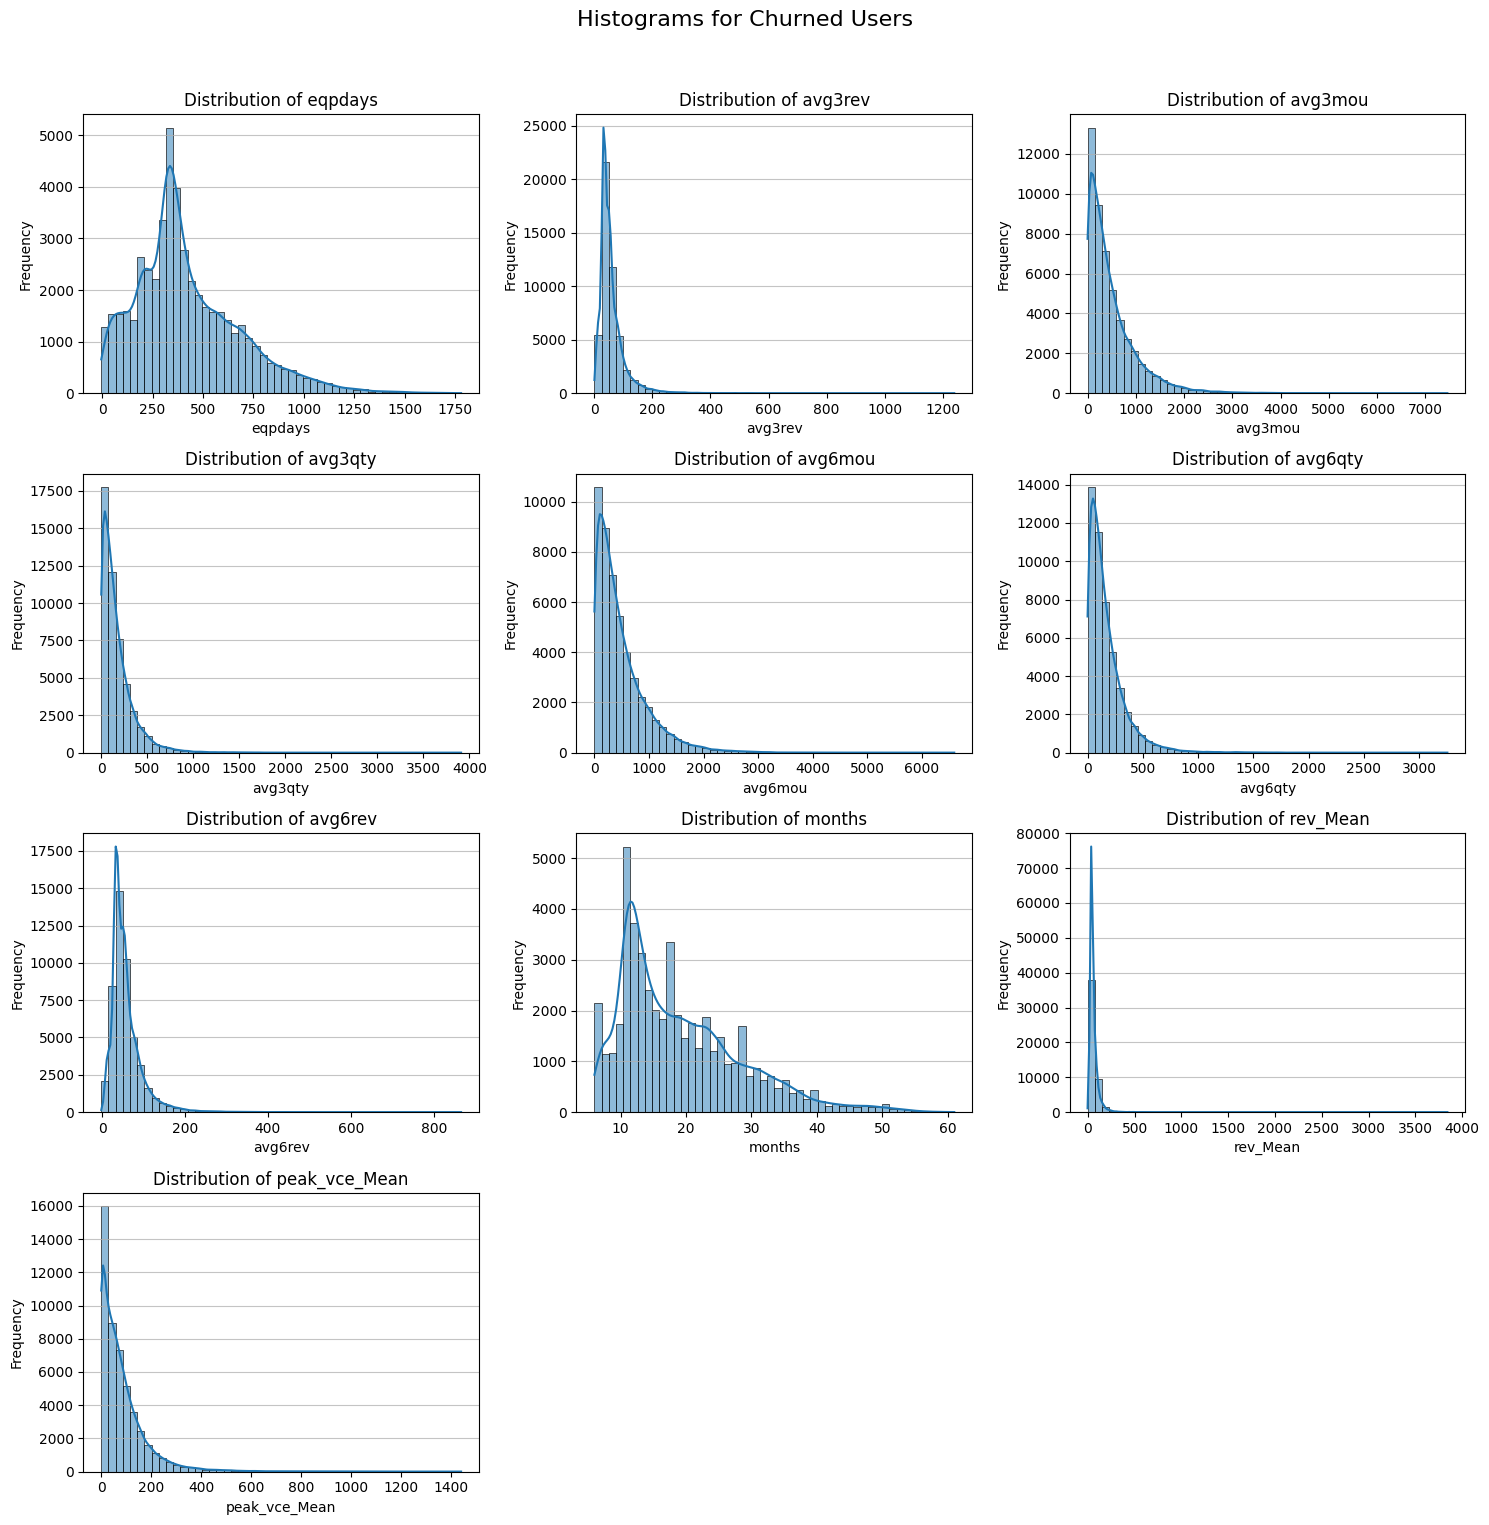

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for churned users
churned_users = merged_data[merged_data['churn'] == 1]

# Attributes to plot
attributes_to_plot = ['eqpdays', 'avg3rev', 'avg3mou', 'avg3qty', 'avg6mou', 'avg6qty', 'avg6rev', 'months', 'rev_Mean', 'peak_vce_Mean']

# Determine grid size (e.g., 3 columns)
num_attributes = len(attributes_to_plot)
num_cols = 3
num_rows = (num_attributes + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 5, num_rows * 4))
fig.suptitle('Histograms for Churned Users', fontsize=16)
axes = axes.flatten()

for i, col in enumerate(attributes_to_plot):
    sns.histplot(churned_users[col], kde=True, bins=50, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].grid(axis='y', alpha=0.75)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(rect=[0, 0.03, 1, 0.96]) # Adjust rect to prevent title overlap
plt.show()

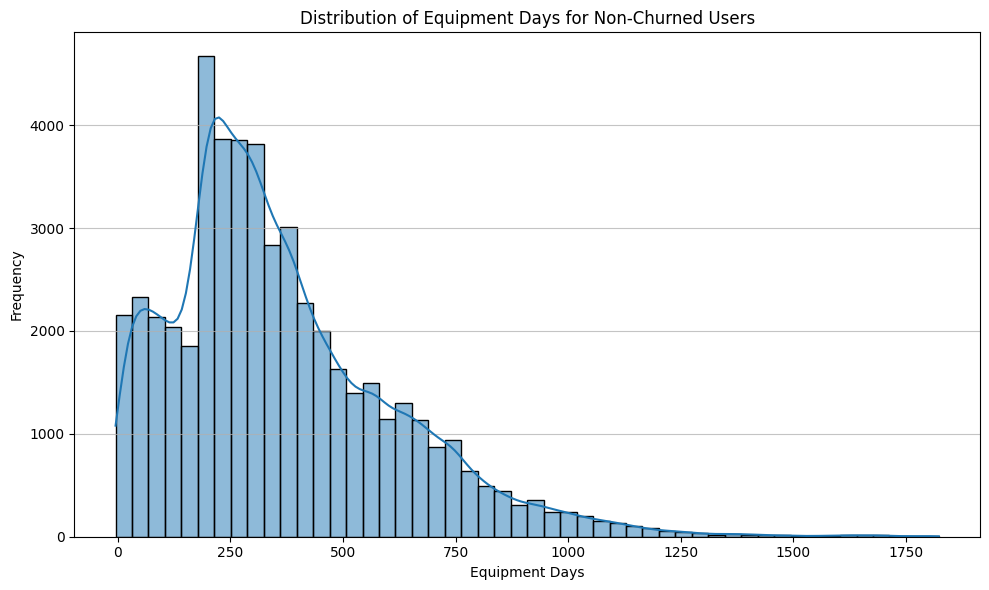

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter for non-churned users
non_churned_users = merged_data[merged_data['churn'] == 0]

plt.figure(figsize=(10, 6))
sns.histplot(non_churned_users['eqpdays'], kde=True, bins=50)
plt.title('Distribution of Equipment Days for Non-Churned Users')
plt.xlabel('Equipment Days')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:14:51] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


ROC-AUC Score: 0.6509


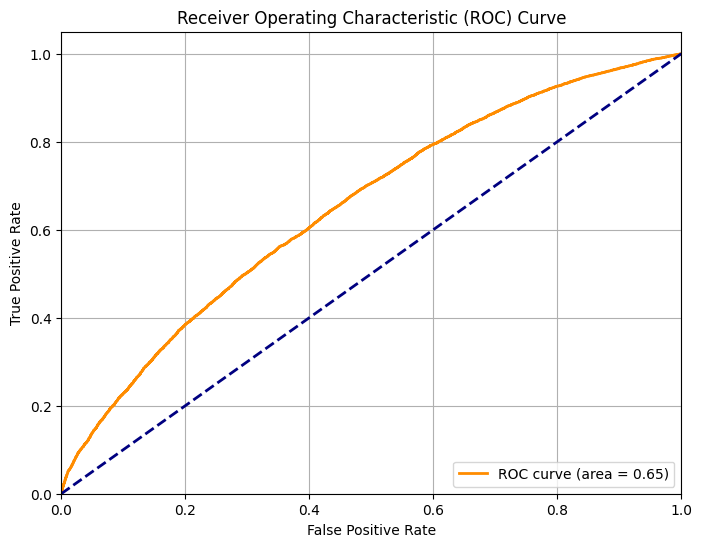

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Define the features and the target variable
features = [
    'change_mou', 'change_rev', 'mou_Mean',
    'peak_vce_Mean', 'threeway_Mean', 'callwait_Mean', 'owylis_vce_Mean',
    'months', 'eqpdays', 'roam_Mean', 'ovrmou_Mean', 'custcare_Mean', 'rev_Mean',
    'vce_comp_rate'
]
target = 'churn'

# Prepare the data
X = merged_data[features]
y = merged_data[target]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the XGBoost classifier
model = xgb.XGBClassifier(objective='binary:logistic', eval_metric='logloss', use_label_encoder=False, random_state=42)
model.fit(X_train, y_train)

# Predict probabilities on the test set
y_pred_proba = model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score
roc_auc = auc(roc_curve(y_test, y_pred_proba)[0], roc_curve(y_test, y_pred_proba)[1])
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC-AUC curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

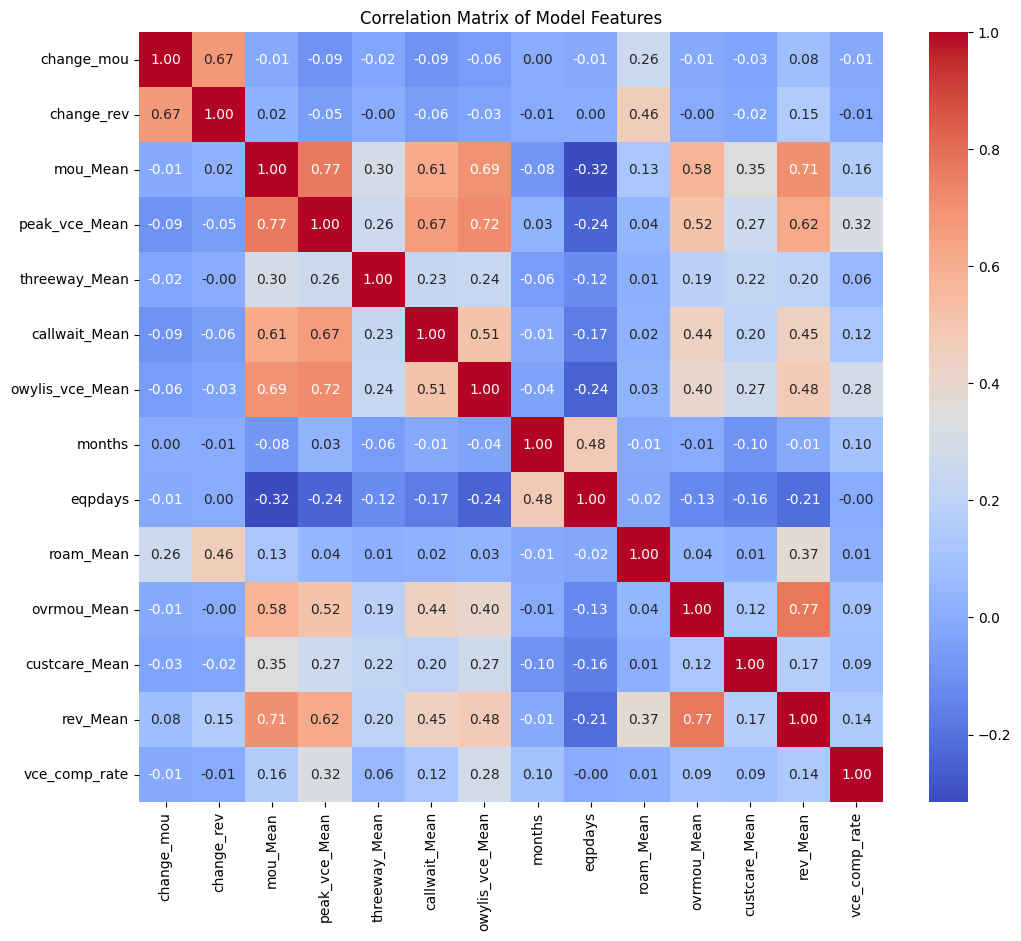

In [ ]:
plt.figure(figsize=(12, 10))
correlation_matrix_features = merged_data[features].corr()
sns.heatmap(correlation_matrix_features, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Model Features')
plt.show()

add new feature = diff_mou-> will calcualte the difference between avg6mou and avg3mou and mou_Mean / the decrease in mou is a good indicator.

### Feature Engineering: `diff_mou`

I will create new features to quantify the decrease in Minutes of Use (MOU) over time, which can be a strong indicator of disengagement and potential churn.

-   `diff_mou_6_months`: Represents the difference between the 6-month average MOU (`avg6mou`) and the current mean MOU (`mou_Mean`). A positive value indicates a decrease in recent MOU compared to the 6-month average.
-   `diff_mou_3_months`: Represents the difference between the 3-month average MOU (`avg3mou`) and the current mean MOU (`mou_Mean`). A positive value indicates a decrease in recent MOU compared to the 3-month average.

In [ ]:
merged_data['diff_mou_6_months'] = merged_data['avg6mou'] - merged_data['mou_Mean']
merged_data['diff_mou_3_months'] = merged_data['avg3mou'] - merged_data['mou_Mean']

print("New features added to merged_data:")
display(merged_data[['avg6mou', 'mou_Mean', 'diff_mou_6_months', 'diff_mou_3_months']].head())

New features added to merged_data:


,avg6mou,mou_Mean,diff_mou_6_months,diff_mou_3_months
0,322.0,219.25,102.75,52.75
1,477.0,482.75,-5.75,-177.75
2,11.0,10.25,0.75,1.75
3,50.0,7.50,42.50,0.50
4,586.0,570.50,15.50,-12.50


### Feature Engineering: Usage Trend and Acceleration Features

I will create features that capture various trends in Minutes of Use (MOU), Revenue (REV), and Quantity (QTY) to better understand customer behavior over different timeframes and identify accelerating declines.

-   **`mou_3_6_diff`**, **`rev_3_6_diff`**, **`qty_3_6_diff`**: Differences between 3-month and 6-month averages to capture short-term vs. long-term trends.
-   **`mou_curr_3_diff`**, **`rev_curr_3_diff`**: Differences between current mean usage/revenue and 3-month averages to identify recent changes.
-   **`mou_acceleration`**: Indicates if the decline in MOU is speeding up, calculated as the difference between `mou_curr_3_diff` and `mou_3_6_diff`.

In [ ]:
merged_data['mou_3_6_diff'] = merged_data['avg3mou'] - merged_data['avg6mou']
merged_data['rev_3_6_diff'] = merged_data['avg3rev'] - merged_data['avg6rev']
merged_data['qty_3_6_diff'] = merged_data['avg3qty'] - merged_data['avg6qty']

merged_data['mou_curr_3_diff'] = merged_data['mou_Mean'] - merged_data['avg3mou']
merged_data['rev_curr_3_diff'] = merged_data['rev_Mean'] - merged_data['avg3rev']

merged_data['mou_acceleration'] = merged_data['mou_curr_3_diff'] - merged_data['mou_3_6_diff']

print("Usage trend and acceleration features added:")
display(merged_data[['mou_3_6_diff', 'rev_3_6_diff', 'qty_3_6_diff', 'mou_curr_3_diff', 'rev_curr_3_diff', 'mou_acceleration']].head())

Usage trend and acceleration features added:


,mou_3_6_diff,rev_3_6_diff,qty_3_6_diff,mou_curr_3_diff,rev_curr_3_diff,mou_acceleration
0,-50.0,-8.0,-20.0,-52.75,-6.0025,-2.75
1,-172.0,-8.0,-117.0,177.75,17.4925,349.75
2,1.0,0.0,1.0,-1.75,-0.0100,-2.75
3,-42.0,-2.0,-22.0,-0.50,0.0000,41.50
4,-28.0,-25.0,-5.0,12.50,0.2300,40.50


### Feature Engineering: Financial Efficiency and Overage Ratios

I will introduce features that highlight financial aspects of usage, such as revenue per minute, overage behavior, and plan efficiency.

-   **`rev_per_mou`**: Revenue per minute of use. A high value with declining MOU could indicate overpaying.
-   **`overage_ratio`**: Overage minutes as a proportion of total MOU. A high ratio suggests the customer is on the wrong plan.
-   **`plan_efficiency`**: MOU per dollar of recurring charge. Low efficiency indicates paying a lot for little usage.
-   **`ovrrev_ratio`**: Overage revenue as a percentage of total mean revenue.

In [ ]:
merged_data['rev_per_mou'] = merged_data['rev_Mean'] / (merged_data['mou_Mean'] + 1)
merged_data['overage_ratio'] = merged_data['ovrmou_Mean'] / (merged_data['mou_Mean'] + 1)
merged_data['plan_efficiency'] = merged_data['mou_Mean'] / (merged_data['totmrc_Mean'] + 1)
merged_data['ovrrev_ratio'] = merged_data['ovrrev_Mean'] / (merged_data['rev_Mean'] + 1)

print("Financial efficiency and overage features added:")
display(merged_data[['rev_per_mou', 'overage_ratio', 'plan_efficiency', 'ovrrev_ratio']].head())

Financial efficiency and overage features added:


,rev_per_mou,overage_ratio,plan_efficiency,ovrrev_ratio
0,0.108956,0.000000,9.329787,0.000000
1,0.118848,0.047028,12.563435,0.155576
2,1.510222,0.000000,0.569761,0.000000
3,4.470588,0.000000,0.192308,0.000000
4,0.096640,0.000000,7.817210,0.000000


### Feature Engineering: Call Quality and Engagement Metrics

These features will focus on call quality issues and specific engagement patterns that might indicate frustration or disinterest.

-   **`drop_rate`**, **`block_rate`**, **`total_fail_rate`**: Rates of dropped, blocked, and total failed voice calls.
-   **`short_call_ratio`**: Proportion of short calls, potentially indicating poor connection or frustration.
-   **`peak_opk_ratio`**: Ratio of peak-hour voice calls to off-peak voice calls, indicating usage patterns.
-   **`wireless_ratio`**: Engagement with 'own wireless' calls relative to total MOU.
-   **`care_per_mou`**: Customer care calls per minute of use, suggesting frustration if high.
-   **`roam_ratio`**: Roaming usage as a proportion of total MOU.

In [ ]:
merged_data['drop_rate'] = merged_data['drop_vce_Mean'] / (merged_data['plcd_vce_Mean'] + 1)
merged_data['block_rate'] = merged_data['blck_vce_Mean'] / (merged_data['plcd_vce_Mean'] + 1)
merged_data['total_fail_rate'] = (merged_data['drop_vce_Mean'] + merged_data['blck_vce_Mean']) / (merged_data['plcd_vce_Mean'] + 1)
merged_data['short_call_ratio'] = merged_data['inonemin_Mean'] / (merged_data['plcd_vce_Mean'] + 1)

merged_data['peak_opk_ratio'] = merged_data['peak_vce_Mean'] / (merged_data['opk_vce_Mean'] + 1)
merged_data['wireless_ratio'] = merged_data['owylis_vce_Mean'] / (merged_data['mou_Mean'] + 1)
merged_data['care_per_mou'] = merged_data['custcare_Mean'] / (merged_data['mou_Mean'] + 1)
merged_data['roam_ratio'] = merged_data['roam_Mean'] / (merged_data['mou_Mean'] + 1)

print("Call quality and engagement features added:")
display(merged_data[['drop_rate', 'block_rate', 'total_fail_rate', 'short_call_ratio', 'peak_opk_ratio', 'wireless_ratio', 'care_per_mou', 'roam_ratio']].head())

Call quality and engagement features added:


,drop_rate,block_rate,total_fail_rate,short_call_ratio,peak_opk_ratio,wireless_ratio,care_per_mou,roam_ratio
0,0.012500,0.012500,0.025000,0.337500,2.320000,0.000000,0.000000,0.0
1,0.031526,0.003783,0.035309,0.200504,0.529536,0.095780,0.003445,0.0
2,0.033333,0.000000,0.033333,0.033333,2.500000,0.000000,0.000000,0.0
3,0.000000,0.000000,0.000000,0.285714,0.285714,0.039216,0.000000,0.0
4,0.043284,0.002985,0.046269,0.295522,1.065693,0.025663,0.015165,0.0


### Feature Engineering: Risk Flags

Finally, I will create binary risk flags and a combined risk score to directly encode insights derived from the EDA.

-   **`renewal_risk`**: A flag indicating if the customer is within a critical tenure window (10 to 17 months) often associated with higher churn.
-   **`silent_churn_risk`**: A composite score combining indicators of declining usage, critical tenure, high overage, and frequent customer care interactions.

In [ ]:
merged_data['renewal_risk'] = merged_data['months'].between(10, 17).astype(int)
merged_data['silent_churn_risk'] = (
    (merged_data['change_mou'] < -15).astype(int) +
    (merged_data['months'].between(10, 17)).astype(int) +
    (merged_data['overage_ratio'] > 0.1).astype(int) +
    (merged_data['care_per_mou'] > merged_data['care_per_mou'].median()).astype(int)
)

print("Risk flag features added:")
display(merged_data[['renewal_risk', 'silent_churn_risk']].head())

Risk flag features added:


,renewal_risk,silent_churn_risk
0,0,1
1,0,1
2,0,0
3,0,0
4,0,1


### Re-evaluating the Model with All New Features

Now, I will include all the newly created features in the model training to see if they improve the churn prediction performance (ROC-AUC score).

### Re-evaluating the Model with New Features

Now, I will include these new `diff_mou` features in the model training to see if they improve the churn prediction performance (ROC-AUC score).

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:14:54] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Updated ROC-AUC Score with new features: 0.6732


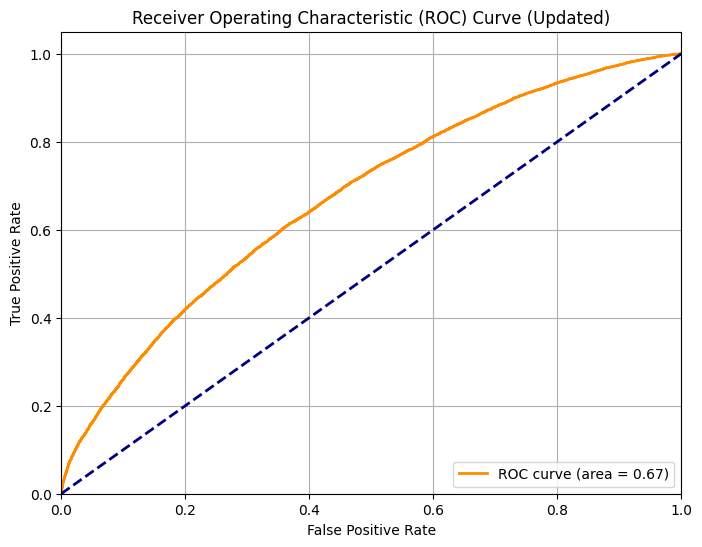

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Create a new features list to include the newly created diff_mou features
updated_features = features.copy()

# Adding all the newly engineered features
updated_features.extend([
    'diff_mou_6_months', 'diff_mou_3_months', 'mou_3_6_diff', 'rev_3_6_diff',
    'qty_3_6_diff', 'mou_curr_3_diff', 'rev_curr_3_diff', 'mou_acceleration',
    'rev_per_mou', 'overage_ratio', 'plan_efficiency', 'ovrrev_ratio',
    'drop_rate', 'block_rate', 'total_fail_rate', 'short_call_ratio',
    'peak_opk_ratio', 'wireless_ratio', 'care_per_mou', 'roam_ratio',
    'renewal_risk', 'silent_churn_risk'
])

# Prepare the data with updated features
X = merged_data[updated_features]
y = merged_data[target]

# Calculate the churn ratio for scale_pos_weight
# This helps handle class imbalance by giving more weight to the minority class
churn_counts = y.value_counts()
ratio = float(churn_counts[0]) / churn_counts[1]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the XGBoost classifier
model_updated = xgb.XGBClassifier(
    n_estimators=500,          # more trees
    max_depth=6,               # slightly deeper
    learning_rate=0.03,        # slower learning = better generalization
    scale_pos_weight=ratio,    # address class imbalance
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=5,        # prevents overfitting on rare patterns
    gamma=0.1,                 # regularization
    reg_alpha=0.1,             # L1
    reg_lambda=1.0,            # L2
    objective='binary:logistic', # Specify objective for binary classification
    eval_metric='logloss',     # Evaluation metric
    use_label_encoder=False,   # Deprecated, set to False
    random_state=42
)
model_updated.fit(X_train, y_train)

# Predict probabilities on the test set
y_pred_proba_updated = model_updated.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score
fpr_updated, tpr_updated, thresholds_updated = roc_curve(y_test, y_pred_proba_updated)
roc_auc_updated = auc(fpr_updated, tpr_updated)
print(f"Updated ROC-AUC Score with new features: {roc_auc_updated:.4f}")

# Plot the ROC-AUC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_updated, tpr_updated, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_updated:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Updated)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
print("Correlation of new features with 'churn':")
display(merged_data[['churn', 'diff_mou_6_months', 'diff_mou_3_months']].corr()['churn'].drop('churn'))

Correlation of new features with 'churn':


,churn
diff_mou_6_months,0.050425
diff_mou_3_months,0.031965


### Hyperparameter Tuning with GridSearchCV

I will use `GridSearchCV` to systematically search for the best combination of hyperparameters that maximizes the model's performance (ROC-AUC).

**Note**: This process can be computationally intensive and may take some time to complete, depending on the size of the parameter grid and the dataset.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid to search
param_grid = {
    'n_estimators': [200, 500],
    'max_depth': [3, 6],
    'learning_rate': [0.01, 0.1],
    'subsample': [0.7, 0.9],
    'colsample_bytree': [0.7, 0.9]
}

# Initialize the XGBoost classifier with fixed parameters (like objective, eval_metric, scale_pos_weight)
# These were determined to be good general settings in the previous step.
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False, # Set to False to avoid warning
    random_state=42,
    scale_pos_weight=ratio # Use the previously calculated ratio for class imbalance
)

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3, # Using 3-fold cross-validation for speed, consider more for robustness
    verbose=2, # Detailed output during the search
    n_jobs=-1 # Use all available cores
)

# Fit GridSearchCV to the training data
grid_search.fit(X_train, y_train)

print("Best hyperparameters found:", grid_search.best_params_)
print("Best ROC-AUC score (from cross-validation):", grid_search.best_score_)


Fitting 3 folds for each of 32 candidates, totalling 96 fits


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:23:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best hyperparameters found: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 6, 'n_estimators': 500, 'subsample': 0.7}
Best ROC-AUC score (from cross-validation): 0.6660381589292987


### Retraining the Model with Optimized Hyperparameters

After finding the best hyperparameters, I will retrain the XGBoost model using these optimized settings and evaluate its performance on the test set.

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:23:14] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Optimized ROC-AUC Score with best parameters: 0.6718


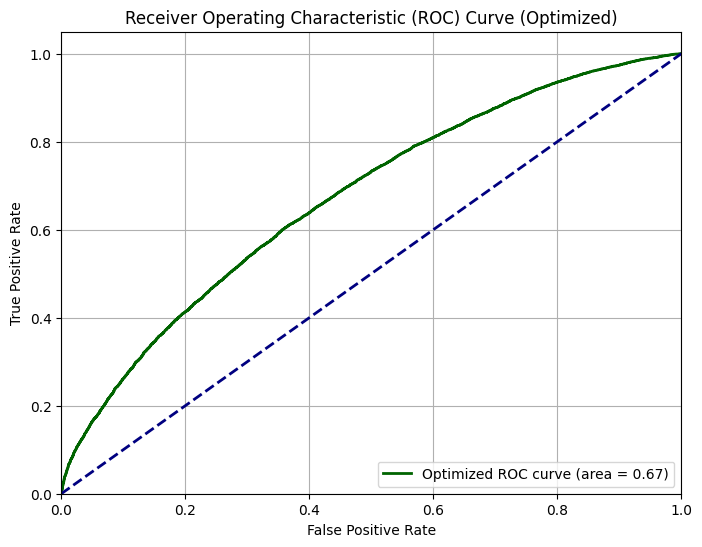

In [ ]:
# Retrain the model with the best parameters found by GridSearchCV
best_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False, # Set to False to avoid warning
    random_state=42,
    scale_pos_weight=ratio, # Use the previously calculated ratio for class imbalance
    **grid_search.best_params_ # Unpack the best parameters found
)

best_model.fit(X_train, y_train)

# Predict probabilities on the test set with the best model
y_pred_proba_optimized = best_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score
fpr_optimized, tpr_optimized, thresholds_optimized = roc_curve(y_test, y_pred_proba_optimized)
roc_auc_optimized = auc(fpr_optimized, tpr_optimized)
print(f"Optimized ROC-AUC Score with best parameters: {roc_auc_optimized:.4f}")

# Plot the ROC-AUC curve for the optimized model
plt.figure(figsize=(8, 6))
plt.plot(fpr_optimized, tpr_optimized, color='darkgreen', lw=2, label=f'Optimized ROC curve (area = {roc_auc_optimized:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Optimized)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


Using **Logistic Regression**

Logistic Regression ROC-AUC Score (with strict leakage-free imputation): 0.6255


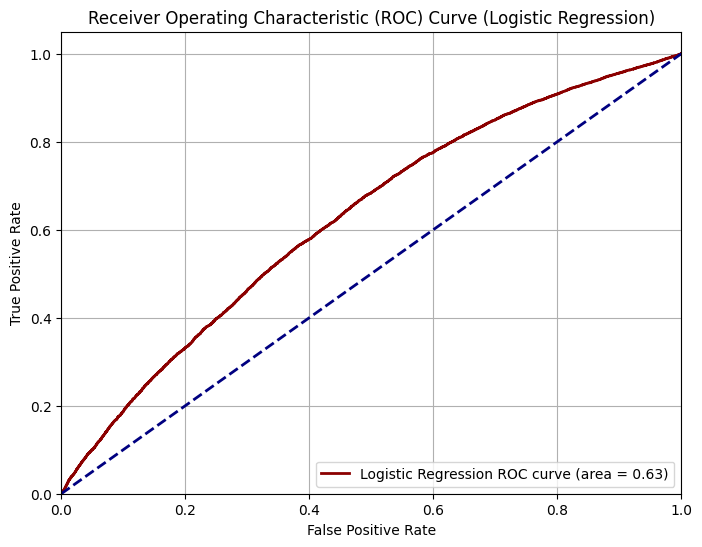

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Initialize Imputer and Scaler
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()

# 1. Fit the imputer ONLY on X_train to prevent leakage
imputer.fit(X_train)

# 2. Transform both datasets using the training median
X_train_imputed = imputer.transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Fit on training data and transform both training and test data
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

# Initialize and train the Logistic Regression model
log_reg_model = LogisticRegression(random_state=42, solver='liblinear', class_weight='balanced')
log_reg_model.fit(X_train_scaled, y_train)

# Predict probabilities on the test set
y_pred_proba_log_reg = log_reg_model.predict_proba(X_test_scaled)[:, 1]

# Calculate ROC-AUC score
fpr_log_reg, tpr_log_reg, thresholds_log_reg = roc_curve(y_test, y_pred_proba_log_reg)
roc_auc_log_reg = auc(fpr_log_reg, tpr_log_reg)
print(f"Logistic Regression ROC-AUC Score (with strict leakage-free imputation): {roc_auc_log_reg:.4f}")

# Plot the ROC-AUC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_log_reg, tpr_log_reg, color='darkred', lw=2, label=f'Logistic Regression ROC curve (area = {roc_auc_log_reg:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Logistic Regression)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

##more **EDA** on other attributes

### Income vs Churn Rate
Let's analyze the churn rate across different income levels to see if lower-income users churn more frequently.

In [ ]:
print("Income vs Churn Rate:")
print(merged_data.groupby('income')['churn'].mean().sort_values(ascending=False))

Income vs Churn Rate:
income
7.0    0.504355
1.0    0.493181
6.0    0.491118
8.0    0.489887
5.0    0.487012
9.0    0.484446
4.0    0.481643
3.0    0.479074
2.0    0.470796
Name: churn, dtype: float64


### Income vs Plan Fit
Now, let's examine if there's a correlation between income levels and how well users fit their plans, by looking at mean revenue, overage minutes, and change in monthly minutes of use.

In [ ]:
print("Income vs Plan Fit (mean revenue, overage, change in MOU):")
print(merged_data.groupby('income')[['rev_Mean', 'ovrmou_Mean', 'change_mou']].mean())

Income vs Plan Fit (mean revenue, overage, change in MOU):
         rev_Mean  ovrmou_Mean  change_mou
income                                    
1.0     63.911865    46.725010    1.004928
2.0     60.085368    42.933267   -0.801642
3.0     59.520376    41.923930  -13.570933
4.0     57.166777    39.824686  -12.885806
5.0     56.618649    39.476605  -13.371603
6.0     55.402825    37.517994  -13.382744
7.0     55.531604    37.293553  -11.704096
8.0     56.734423    37.954902  -12.379400
9.0     55.008755    34.105734  -13.438243


We can see that income cateogries are giving **strong signal** about relation with change in minutes of use so we will use this attribute also in model training

the income category above 3 show declining engagement through change_mou.

the category 2 is **stable** with change_mou barely negative

the category 1 is **growing** category in terms of engagement

### Marital Status vs Churn Rate
Investigating if marital status influences churn, with the hypothesis that married individuals might be more stable and thus less likely to churn.

In [ ]:
print("Marital Status vs Churn Rate:")
print(merged_data.groupby('marital')['churn'].mean())

Marital Status vs Churn Rate:
marital
A    0.489689
B    0.496908
M    0.488664
S    0.474670
U    0.512656
Name: churn, dtype: float64


### Subscriber Count vs Churn Rate
Exploring the churn rate based on the number of unique (`uniqsubs`) and active (`actvsubs`) subscribers, hypothesizing that family plans (more active subscribers) are stickier.

In [ ]:
print("Unique Subscribers vs Churn Rate:")
print(merged_data.groupby('uniqsubs')['churn'].mean())

print("\nActive Subscribers vs Churn Rate:")
print(merged_data.groupby('actvsubs')['churn'].mean())

Unique Subscribers vs Churn Rate:
uniqsubs
1      0.476665
2      0.522246
3      0.528652
4      0.548905
5      0.534132
6      0.574603
7      0.612613
8      0.700000
9      0.700000
10     0.777778
11     0.800000
12     0.250000
13     1.000000
18     1.000000
196    1.000000
Name: churn, dtype: float64

Active Subscribers vs Churn Rate:
actvsubs
0     0.407407
1     0.486728
2     0.522152
3     0.491790
4     0.513904
5     0.423664
6     0.500000
7     0.400000
8     0.833333
9     1.000000
11    0.000000
53    1.000000
Name: churn, dtype: float64


**uniqsubs** is a significant signal as the churn probability increases with increase in the uniqsubs in a household.
so we should add this attribute in model training

### Adults in Household vs Churn Rate
Analyzing the churn rate in relation to the number of adults in the household.

In [ ]:
print("Adults in Household vs Churn Rate:")
print(merged_data.groupby('adults')['churn'].mean())

Adults in Household vs Churn Rate:
adults
1.0    0.490605
2.0    0.494858
3.0    0.487598
4.0    0.480291
5.0    0.485572
6.0    0.478621
Name: churn, dtype: float64


### Kids Present vs Churn Rate
Creating a 'has_kids' feature and examining its impact on churn, with the hypothesis that families might churn less due to being more embedded in the service.

In [ ]:
merged_data['has_kids'] = ((merged_data['kid0_2'].apply(lambda x: 1 if x == 'Y' else 0) +
                   merged_data['kid3_5'].apply(lambda x: 1 if x == 'Y' else 0) +
                   merged_data['kid6_10'].apply(lambda x: 1 if x == 'Y' else 0) +
                   merged_data['kid11_15'].apply(lambda x: 1 if x == 'Y' else 0) +
                   merged_data['kid16_17'].apply(lambda x: 1 if x == 'Y' else 0)) > 0).astype(int)

print("Has Kids vs Churn Rate:")
print(merged_data.groupby('has_kids')['churn'].mean())

Has Kids vs Churn Rate:
has_kids
0    0.494547
1    0.499143
Name: churn, dtype: float64


Lets visualize few attributes to infer what does income categories refer to.

/tmp/ipykernel_995/4159895565.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='hnd_price', data=merged_data, ax=axes[0], palette='viridis')
/tmp/ipykernel_995/4159895565.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='numbcars', data=merged_data, ax=axes[1], palette='plasma')


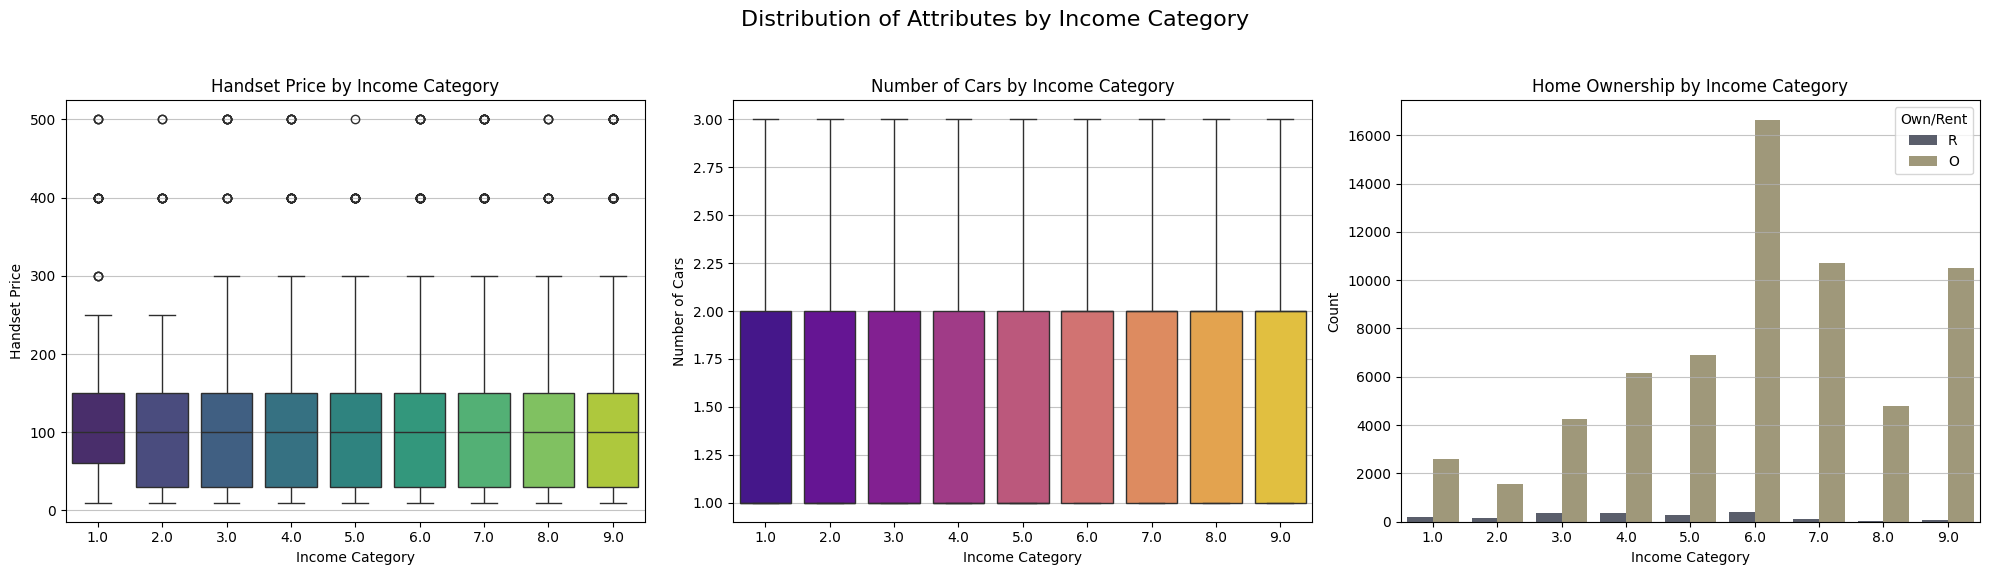

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Distribution of Attributes by Income Category', fontsize=16)

# Plot 1: Income vs Hnd Price (Boxplot is good for numerical vs categorical)
sns.boxplot(x='income', y='hnd_price', data=merged_data, ax=axes[0], palette='viridis')
axes[0].set_title('Handset Price by Income Category')
axes[0].set_xlabel('Income Category')
axes[0].set_ylabel('Handset Price')
axes[0].grid(axis='y', alpha=0.75)

# Plot 2: Income vs Numbcars (Boxplot or violin plot is good)
sns.boxplot(x='income', y='numbcars', data=merged_data, ax=axes[1], palette='plasma')
axes[1].set_title('Number of Cars by Income Category')
axes[1].set_xlabel('Income Category')
axes[1].set_ylabel('Number of Cars')
axes[1].grid(axis='y', alpha=0.75)

# Plot 3: Income vs Ownrent (Countplot for categorical vs categorical)
sns.countplot(x='income', hue='ownrent', data=merged_data, ax=axes[2], palette='cividis')
axes[2].set_title('Home Ownership by Income Category')
axes[2].set_xlabel('Income Category')
axes[2].set_ylabel('Count')
axes[2].grid(axis='y', alpha=0.75)
axes[2].legend(title='Own/Rent')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

from the above analysis it is clear that there is no strong differentiation between income categories so we cannot make a hypothesis from this but we will include this in model training.

### Feature Engineering: Multi-Subscriber Risk

I will create a `multi_sub_risk` feature to identify households with multiple unique subscribers, as this has been identified as a significant signal for churn.

In [ ]:
merged_data['multi_sub_risk'] = (merged_data['uniqsubs'] > 3).astype(int)

print("New 'multi_sub_risk' feature added:")
display(merged_data[['uniqsubs', 'multi_sub_risk']].head())

New 'multi_sub_risk' feature added:


,uniqsubs,multi_sub_risk
0,2,0
1,1,0
2,1,0
3,1,0
4,1,0


### Re-evaluating the Model with Additional New Features

Now, I will include the newly created `multi_sub_risk` feature and the `income` attribute into the feature set for model training. This will involve re-running the model training and evaluation steps with these additional predictive signals.

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [04:23:33] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Updated ROC-AUC Score with new features (2): 0.6760


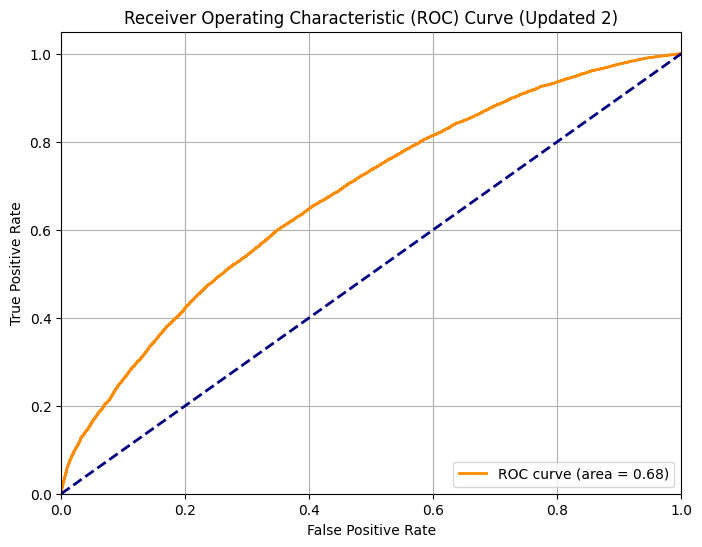

In [ ]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# --- Fix: Ensure engineered features exist in merged_data ---
if 'multi_sub_risk' not in merged_data.columns:
    merged_data['multi_sub_risk'] = (merged_data['uniqsubs'] > 3).astype(int)

# Create a new features list to include the newly created diff_mou features
updated_features = features.copy()

# Adding all the previously engineered features
updated_features.extend([
    'diff_mou_6_months', 'diff_mou_3_months', 'mou_3_6_diff', 'rev_3_6_diff',
    'qty_3_6_diff', 'mou_curr_3_diff', 'rev_curr_3_diff', 'mou_acceleration',
    'rev_per_mou', 'overage_ratio', 'plan_efficiency', 'ovrrev_ratio',
    'drop_rate', 'block_rate', 'total_fail_rate', 'short_call_ratio',
    'peak_opk_ratio', 'wireless_ratio', 'care_per_mou', 'roam_ratio',
    'renewal_risk', 'silent_churn_risk'
])

# Adding the newly requested features: 'multi_sub_risk' and 'income'
updated_features.extend(['multi_sub_risk', 'income'])

# Prepare the data with updated features
# Note: income might contain NaNs; XGBoost handles them, but ensure it is numeric
X = merged_data[updated_features]
y = merged_data[target]

# Calculate the churn ratio for scale_pos_weight
churn_counts = y.value_counts()
ratio = float(churn_counts[0]) / churn_counts[1]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize and train the XGBoost classifier
model_updated_2 = xgb.XGBClassifier(
    n_estimators=500,          # more trees
    max_depth=6,               # slightly deeper
    learning_rate=0.03,        # slower learning = better generalization
    scale_pos_weight=ratio,    # address class imbalance
    subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=5,        # prevents overfitting on rare patterns
    gamma=0.1,                 # regularization
    reg_alpha=0.1,             # L1
    reg_lambda=1.0,            # L2
    objective='binary:logistic',
    eval_metric='logloss',
    use_label_encoder=False,
    random_state=42
)
model_updated_2.fit(X_train, y_train)

# Predict probabilities on the test set
y_pred_proba_updated_2 = model_updated_2.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score
fpr_updated_2, tpr_updated_2, thresholds_updated_2 = roc_curve(y_test, y_pred_proba_updated_2)
roc_auc_updated_2 = auc(fpr_updated_2, tpr_updated_2)
print(f"Updated ROC-AUC Score with new features (2): {roc_auc_updated_2:.4f}")

# Plot the ROC-AUC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_updated_2, tpr_updated_2, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_updated_2:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve (Updated 2)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

Precision: 0.6212
Recall: 0.6307


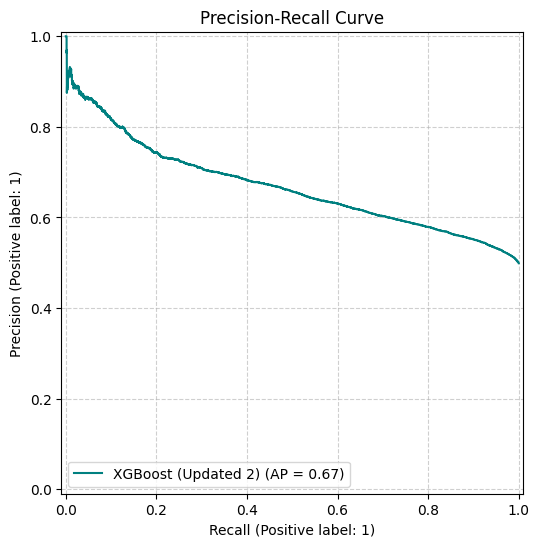

In [ ]:
from sklearn.metrics import precision_score, recall_score, precision_recall_curve, PrecisionRecallDisplay
import matplotlib.pyplot as plt

# Calculate predictions using a 0.5 threshold
y_pred = model_updated_2.predict(X_test)

# Calculate Precision and Recall
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)

print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

# Plot the Precision-Recall Curve
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba_updated_2, name='XGBoost (Updated 2)', color='teal', ax=plt.gca())
plt.title('Precision-Recall Curve')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score

# Set the new threshold
threshold = 0.38

# Convert probabilities to binary predictions based on the 0.4 threshold
y_pred_04 = (y_pred_proba_updated_2 >= threshold).astype(int)

# Calculate Precision and Recall at this threshold
precision_04 = precision_score(y_test, y_pred_04)
recall_04 = recall_score(y_test, y_pred_04)

print(f'Results at Threshold {threshold}:')
print(f'Precision: {precision_04:.4f}')
print(f'Recall: {recall_04:.4f}')

Results at Threshold 0.38:
Precision: 0.5585
Recall: 0.8732


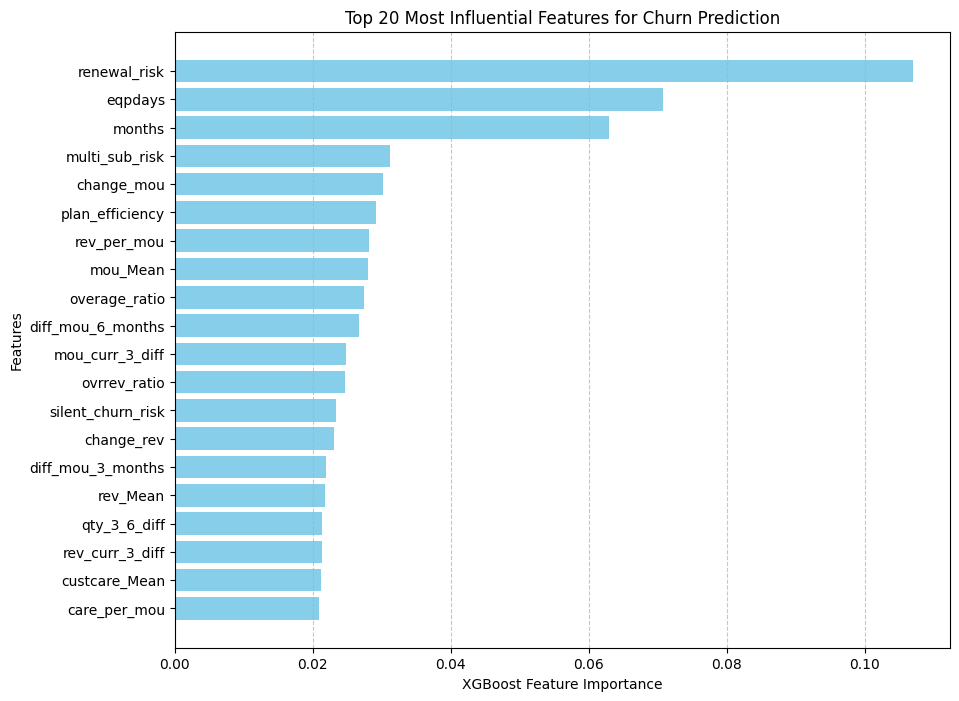

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
importances = model_updated_2.feature_importances_
feature_names = updated_features

# Create a DataFrame for visualization
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Plot the top 20 features
plt.figure(figsize=(10, 8))
plt.barh(feature_importance_df['Feature'].head(20), feature_importance_df['Importance'].head(20), color='skyblue')
plt.xlabel('XGBoost Feature Importance')
plt.ylabel('Features')
plt.title('Top 20 Most Influential Features for Churn Prediction')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

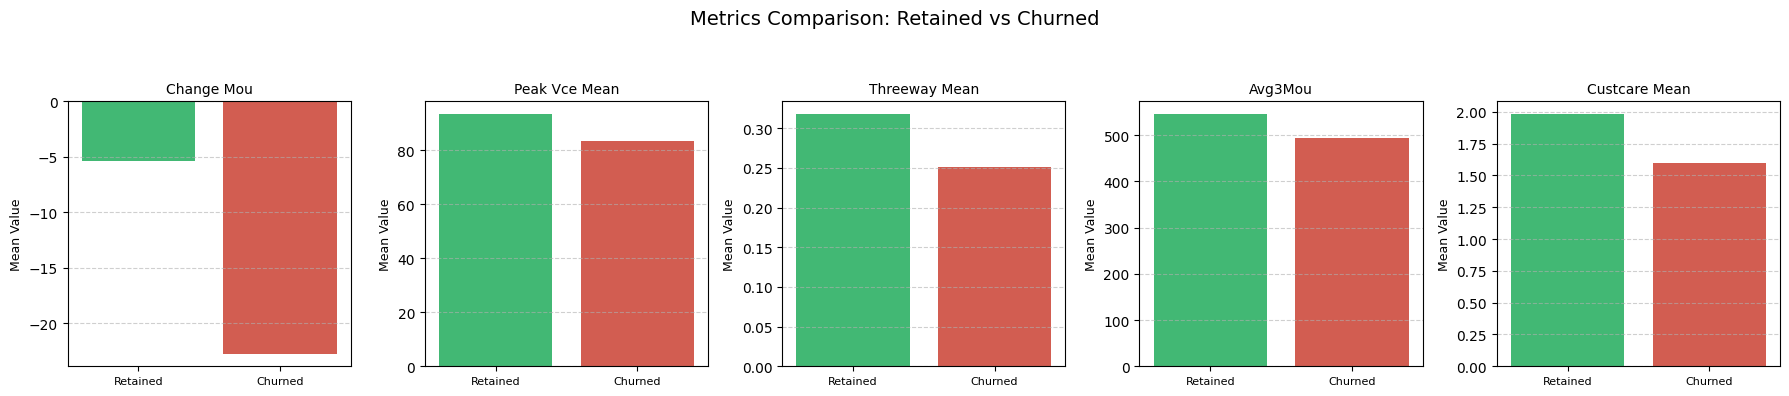

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Metrics to compare (aligned with previous analysis)
metrics_to_compare = ['change_mou', 'peak_vce_Mean', 'threeway_Mean', 'avg3mou', 'custcare_Mean']

# Grouping mean data for plotting
churn_comparison = merged_data.groupby('churn')[metrics_to_compare].mean()

# Create a 1x5 subplot grid for a single row layout
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(18, 4))
fig.suptitle('Metrics Comparison: Retained vs Churned', fontsize=14)

for i, metric in enumerate(metrics_to_compare):
    sns.barplot(x=churn_comparison.index, y=churn_comparison[metric], ax=axes[i],
                palette=['#2ecc71', '#e74c3c'], hue=churn_comparison.index, legend=False)

    axes[i].set_title(metric.replace('_', ' ').title(), fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Mean Value', fontsize=9)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Retained', 'Churned'], fontsize=8)
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

# Using tight_layout to fit everything on screen
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

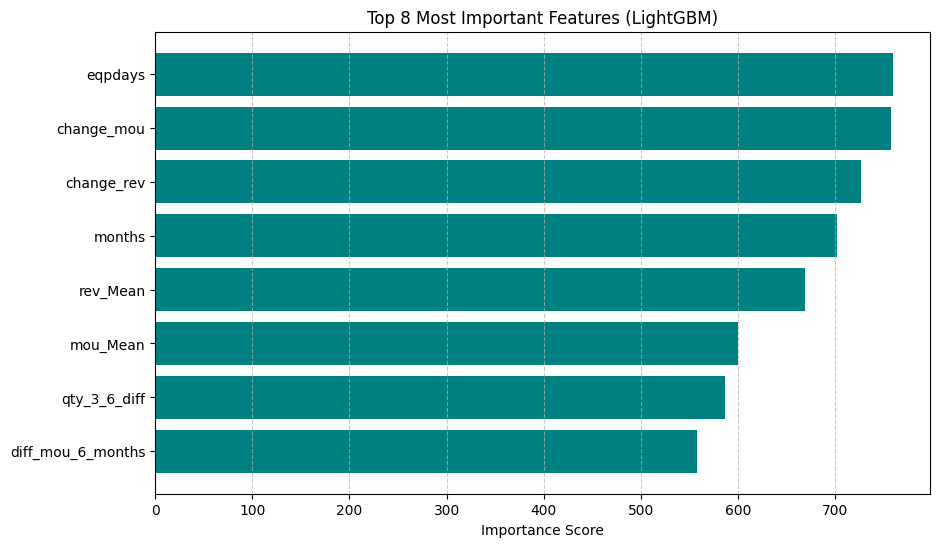

--- Top 8 Feature Descriptions ---
- eqpdays: Number of days the customer has owned their current equipment (longer ownership often correlates with churn).
- change_mou: Percentage change in monthly minutes of use (declining usage is a key indicator of disengagement).
- change_rev: Percentage change in monthly revenue.
- months: Total tenure of the customer in months.
- rev_Mean: Mean monthly revenue generated by the customer.
- mou_Mean: Mean monthly minutes of use.
- qty_3_6_diff: Difference in call quantity between the 3-month and 6-month averages.
- diff_mou_6_months: The decrease in usage calculated by the difference between the 6-month average and current mean MOU.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance from LightGBM
lgb_feat_importance = pd.DataFrame({
    'Feature': updated_features,
    'Importance': lgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(8)

# Mapping technical names to descriptive meanings (including diff_mou_6_months)
feature_descriptions = {
    'eqpdays': 'Number of days the customer has owned their current equipment (longer ownership often correlates with churn).',
    'change_mou': 'Percentage change in monthly minutes of use (declining usage is a key indicator of disengagement).',
    'change_rev': 'Percentage change in monthly revenue.',
    'months': 'Total tenure of the customer in months.',
    'rev_Mean': 'Mean monthly revenue generated by the customer.',
    'mou_Mean': 'Mean monthly minutes of use.',
    'qty_3_6_diff': 'Difference in call quantity between the 3-month and 6-month averages.',
    'diff_mou_6_months': 'The decrease in usage calculated by the difference between the 6-month average and current mean MOU.',
    'plan_efficiency': 'The ratio of usage minutes to the monthly recurring charge (identifies overpaying customers).',
    'mou_curr_3_diff': 'Difference between current usage and the 3-month average.',
    'rev_curr_3_diff': 'Difference between current revenue and the 3-month average.',
    'rev_per_mou': 'Average cost per minute of use.'
}

# Display the top 8 features
plt.figure(figsize=(10, 6))
plt.barh(lgb_feat_importance['Feature'], lgb_feat_importance['Importance'], color='teal')
plt.xlabel('Importance Score')
plt.title('Top 8 Most Important Features (LightGBM)')
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

print("--- Top 8 Feature Descriptions ---")
for feat in lgb_feat_importance['Feature']:
    print(f"- {feat}: {feature_descriptions.get(feat, 'N/A')}")

In [ ]:
# Calculate revenue at risk
churners = merged_data[merged_data['churn'] == 1]
n_churners = len(churners)
avg_monthly_rev = churners['rev_Mean'].mean()
avg_tenure_remaining = 12  # assume could have stayed 1 more year

revenue_at_risk = n_churners * avg_monthly_rev * avg_tenure_remaining

print(f"Total churners: {n_churners}")
print(f"Avg monthly rev per churner: ${avg_monthly_rev:.2f}")
print(f"Annual revenue at risk: ${revenue_at_risk:,.0f}")

Total churners: 49562
Avg monthly rev per churner: $58.21
Annual revenue at risk: $34,620,687


In [ ]:
import pandas as pd

# Calculate total annual revenue for the entire base
total_monthly_rev_all = merged_data['rev_Mean'].sum()
total_annual_rev_all = total_monthly_rev_all * 12

# Calculate percentage of revenue at risk
pct_revenue_at_risk = (revenue_at_risk / total_annual_rev_all) * 100

print(f"Total Projected Annual Revenue: ${total_annual_rev_all:,.0f}")
print(f"Annual Revenue at Risk: ${revenue_at_risk:,.0f}")
print(f"Percentage of Revenue at Risk: {pct_revenue_at_risk:.2f}%")

Total Projected Annual Revenue: $70,212,425
Annual Revenue at Risk: $34,620,687
Percentage of Revenue at Risk: 49.31%


The Revenue Risk due to Churners is **49.31%**
This is very **significant loss** to the Company

So we will test with different threeshold values - we have to identify Churners accurately so we have to identify more churners

# **ROI Analysis**

In [ ]:
import numpy as np
from sklearn.metrics import precision_score, recall_score

# Configuration
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]
intervention_cost = 15        # $ per customer outreach
retention_convert = 0.30      # 30% of intervened customers stay
avg_monthly_rev = 58.21
months_retained = 12
ltv_per_churner = avg_monthly_rev * months_retained

# Calculate baseline for percentages in the test set
n_test = len(y_test)
n_test_churners = y_test.sum()
total_rev_at_risk_test = n_test_churners * ltv_per_churner

# Using probabilities from the updated XGBoost model (model_updated_2)
y_prob = y_pred_proba_updated_2

print(f"--- Test Set Baseline ---")
print(f"Total Customers: {n_test:,}")
print(f"Total Churners: {n_test_churners:,}")
print(f"LTV at risk (Test Set): ${total_rev_at_risk_test:,.0f}\n")

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    p = precision_score(y_test, y_pred_t)
    r = recall_score(y_test, y_pred_t)

    flagged = y_pred_t.sum()
    true_pos = r * n_test_churners

    saved = true_pos * retention_convert * ltv_per_churner
    cost = flagged * intervention_cost
    net = saved - cost
    roi_ratio = saved / cost if cost > 0 else 0

    # Percentage Calculations
    pct_flagged = (flagged / n_test) * 100
    pct_rev_saved = (saved / total_rev_at_risk_test) * 100
    pct_cost_of_risk = (cost / total_rev_at_risk_test) * 100

    print(f"Threshold {t}: P={p:.2f} R={r:.2f} | "
          f"Flagged={flagged:,.0f} ({pct_flagged:.1f}%) | "
          f"Saved=${saved:,.0f} ({pct_rev_saved:.1f}% of Risk) | "
          f"Cost=${cost:,.0f} ({pct_cost_of_risk:.1f}% of Risk) | "
          f"ROI={roi_ratio:.1f}x")

--- Test Set Baseline ---
Total Customers: 30,000
Total Churners: 14,969
LTV at risk (Test Set): $10,456,146

Threshold 0.3: P=0.53 R=0.95 | Flagged=26,666 (88.9%) | Saved=$2,975,905 (28.5% of Risk) | Cost=$399,990 (3.8% of Risk) | ROI=7.4x
Threshold 0.35: P=0.55 R=0.91 | Flagged=24,747 (82.5%) | Saved=$2,849,333 (27.3% of Risk) | Cost=$371,205 (3.6% of Risk) | ROI=7.7x
Threshold 0.4: P=0.57 R=0.84 | Flagged=22,323 (74.4%) | Saved=$2,650,464 (25.3% of Risk) | Cost=$334,845 (3.2% of Risk) | ROI=7.9x
Threshold 0.45: P=0.59 R=0.76 | Flagged=19,180 (63.9%) | Saved=$2,370,497 (22.7% of Risk) | Cost=$287,700 (2.8% of Risk) | ROI=8.2x
Threshold 0.5: P=0.62 R=0.63 | Flagged=15,199 (50.7%) | Saved=$1,978,418 (18.9% of Risk) | Cost=$227,985 (2.2% of Risk) | ROI=8.7x


According to the Analysis
Threshold of 0.35 - saves more than **$2.8 million** with a Good ROI and retaining **27.3%** of the possible leaving users.---For test set


According to this analysis we can save **$14.2 million** in the training set

Comparing **more Models**

In [ ]:
%%capture
!pip install catboost

CatBoost ROC-AUC Score: 0.6718


,Threshold,Precision,Recall
0,0.30,0.5253,0.9612
1,0.35,0.5432,0.9196
2,0.40,0.5583,0.8612
3,0.50,0.6127,0.6507


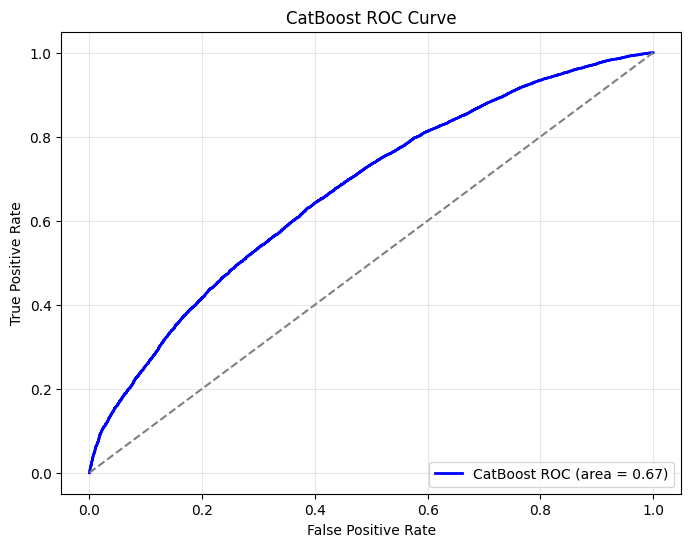

In [ ]:
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, precision_score, recall_score, roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd

# Using the same updated_features list from the previous XGBoost run
# Handling potential NaNs specifically for CatBoost if needed, though it handles them natively
X_cat = merged_data[updated_features]
y_cat = merged_data[target]

# Split using the same random state for consistency
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat, y_cat, test_size=0.3, random_state=42
)

# Initialize and train CatBoost
# We use auto_class_weights to handle the slight imbalance similar to scale_pos_weight
cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.03,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=42,
    verbose=False,
    auto_class_weights='Balanced'
)

cat_model.fit(X_train_cat, y_train_cat)

# Predict probabilities
y_prob_cat = cat_model.predict_proba(X_test_cat)[:, 1]

# Calculate ROC-AUC
roc_auc_cat = roc_auc_score(y_test_cat, y_prob_cat)
print(f"CatBoost ROC-AUC Score: {roc_auc_cat:.4f}")

# Threshold Analysis
eval_thresholds = [0.30, 0.35, 0.40, 0.50]
results = []

for t in eval_thresholds:
    y_pred_t = (y_prob_cat >= t).astype(int)
    prec = precision_score(y_test_cat, y_pred_t)
    rec = recall_score(y_test_cat, y_pred_t)
    results.append({
        'Threshold': t,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4)
    })

results_df = pd.DataFrame(results)
display(results_df)

# Plot ROC Curve
fpr, tpr, _ = roc_curve(y_test_cat, y_prob_cat)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'CatBoost ROC (area = {roc_auc_cat:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('CatBoost ROC Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

LightGBM ROC-AUC Score: 0.6730


,Threshold,Precision,Recall
0,0.30,0.5292,0.9565
1,0.35,0.5461,0.9125
2,0.40,0.5654,0.8478
3,0.50,0.6178,0.6363


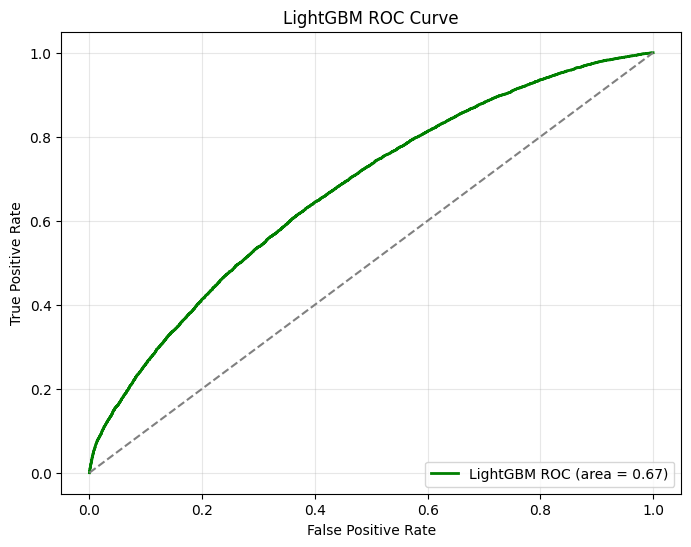

In [ ]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, precision_score, recall_score, roc_curve, auc
import matplotlib.pyplot as plt
import pandas as pd

# Using the consistent feature set and data split
X_lgb = merged_data[updated_features]
y_lgb = merged_data[target]

X_train_lgb, X_test_lgb, y_train_lgb, y_test_lgb = train_test_split(
    X_lgb, y_lgb, test_size=0.3, random_state=42
)

# Initialize and train LightGBM
# is_unbalance=True handles class imbalance similarly to previous models
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    num_leaves=31,
    objective='binary',
    metric='auc',
    random_state=42,
    is_unbalance=True,
    verbose=-1
)

lgb_model.fit(X_train_lgb, y_train_lgb)

# Predict probabilities
y_prob_lgb = lgb_model.predict_proba(X_test_lgb)[:, 1]

# Calculate ROC-AUC
roc_auc_lgb = roc_auc_score(y_test_lgb, y_prob_lgb)
print(f"LightGBM ROC-AUC Score: {roc_auc_lgb:.4f}")

# Threshold Analysis
eval_thresholds = [0.30, 0.35, 0.40, 0.50]
lgb_results = []

for t in eval_thresholds:
    y_pred_t = (y_prob_lgb >= t).astype(int)
    prec = precision_score(y_test_lgb, y_pred_t)
    rec = recall_score(y_test_lgb, y_pred_t)
    lgb_results.append({
        'Threshold': t,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4)
    })

lgb_results_df = pd.DataFrame(lgb_results)
display(lgb_results_df)

# Plot ROC Curve
fpr_lgb, tpr_lgb, _ = roc_curve(y_test_lgb, y_prob_lgb)
plt.figure(figsize=(8, 6))
plt.plot(fpr_lgb, tpr_lgb, color='green', lw=2, label=f'LightGBM ROC (area = {roc_auc_lgb:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LightGBM ROC Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### Final Model Benchmarking
In this section, we compare the ROC-AUC performance of all implemented models to identify the strongest candidate for deployment.

In [ ]:
import pandas as pd

# Consolidating results from all models
comparison_data = {
    'Model': ['Logistic Regression', 'XGBoost (Tuned)', 'CatBoost', 'LightGBM'],
    'ROC-AUC Score': [roc_auc_log_reg, roc_auc_optimized, roc_auc_cat, roc_auc_lgb]
}

benchmark_df = pd.DataFrame(comparison_data).sort_values(by='ROC-AUC Score', ascending=False)
display(benchmark_df)

,Model,ROC-AUC Score
3,LightGBM,0.673038
1,XGBoost (Tuned),0.671830
2,CatBoost,0.671775
0,Logistic Regression,0.625546


### ROI Comparison: LightGBM vs. XGBoost
In this section, we apply the same financial assumptions to the LightGBM model and compare its performance directly against our previous XGBoost results.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import precision_score, recall_score

# Assumptions (consistent with cell 7121ecd9)
intervention_cost = 15
retention_convert = 0.30
avg_monthly_rev = 58.21
months_retained = 12
ltv_per_churner = avg_monthly_rev * months_retained
thresholds = [0.30, 0.35, 0.40, 0.45, 0.50]

n_test = len(y_test_lgb)
n_test_churners = y_test_lgb.sum()
total_rev_at_risk_test = n_test_churners * ltv_per_churner

# Data from previous XGBoost analysis for comparison (manually reconstructed from cell 7121ecd9 output)
xgb_roi_data = {
    0.30: {'saved': 2975905, 'roi': 7.4},
    0.35: {'saved': 2849333, 'roi': 7.7},
    0.40: {'saved': 2650464, 'roi': 7.9},
    0.45: {'saved': 2370497, 'roi': 8.2},
    0.50: {'saved': 1978418, 'roi': 8.7}
}

comparison_results = []

for t in thresholds:
    # LightGBM metrics
    y_pred_lgb = (y_prob_lgb >= t).astype(int)
    p_lgb = precision_score(y_test_lgb, y_pred_lgb)
    r_lgb = recall_score(y_test_lgb, y_pred_lgb)

    flagged_lgb = y_pred_lgb.sum()
    true_pos_lgb = r_lgb * n_test_churners
    saved_lgb = true_pos_lgb * retention_convert * ltv_per_churner
    cost_lgb = flagged_lgb * intervention_cost
    roi_lgb = saved_lgb / cost_lgb if cost_lgb > 0 else 0

    # Percentage Differences
    saved_diff_pct = ((saved_lgb - xgb_roi_data[t]['saved']) / xgb_roi_data[t]['saved']) * 100
    roi_diff_pct = ((roi_lgb - xgb_roi_data[t]['roi']) / xgb_roi_data[t]['roi']) * 100

    comparison_results.append({
        'Threshold': t,
        'LGB_Saved': saved_lgb,
        'LGB_ROI': roi_lgb,
        'Saved_Diff_%': saved_diff_pct,
        'ROI_Diff_%': roi_diff_pct
    })

roi_comp_df = pd.DataFrame(comparison_results)
print("ROI Comparison (LightGBM vs XGBoost):")
display(roi_comp_df.style.format({
    'LGB_Saved': '${:,.0f}',
    'LGB_ROI': '{:.2f}x',
    'Saved_Diff_%': '{:+.2f}%',
    'ROI_Diff_%': '{:+.2f}%'
}))

ROI Comparison (LightGBM vs XGBoost):


,Threshold,LGB_Saved,LGB_ROI,Saved_Diff_%,ROI_Diff_%
0,0.300000,"$3,000,423",7.39x,+0.82%,-0.09%
1,0.350000,"$2,862,325",7.63x,+0.46%,-0.92%
2,0.400000,"$2,659,266",7.90x,+0.33%,-0.01%
3,0.450000,"$2,379,718",8.21x,+0.39%,+0.13%
4,0.500000,"$1,996,021",8.63x,+0.89%,-0.80%


### Logistic Regression: Threshold Analysis
Evaluating Precision and Recall for the Logistic Regression baseline across the requested probability thresholds.

In [ ]:
from sklearn.metrics import precision_score, recall_score

log_reg_thresholds = [0.30, 0.35, 0.40, 0.50]
log_reg_results = []

for t in log_reg_thresholds:
    # Using y_pred_proba_log_reg which was generated in cell 40098f7a
    y_pred_t = (y_pred_proba_log_reg >= t).astype(int)
    prec = precision_score(y_test, y_pred_t)
    rec = recall_score(y_test, y_pred_t)
    log_reg_results.append({
        'Threshold': t,
        'Precision': round(prec, 4),
        'Recall': round(rec, 4)
    })

log_reg_metrics_df = pd.DataFrame(log_reg_results)
print("Logistic Regression Performance at Various Thresholds:")
display(log_reg_metrics_df)

Logistic Regression Performance at Various Thresholds:


,Threshold,Precision,Recall
0,0.30,0.5032,0.9856
1,0.35,0.5180,0.9470
2,0.40,0.5420,0.8710
3,0.50,0.5852,0.6105


### Unified Feature Importance Comparison
In this section, we compare the top features from our best-performing gradient boosting model (LightGBM) with the coefficients of our baseline Logistic Regression model. This dual perspective helps validate if both models are identifying the same underlying behavioral patterns (like equipment tenure and usage decline).

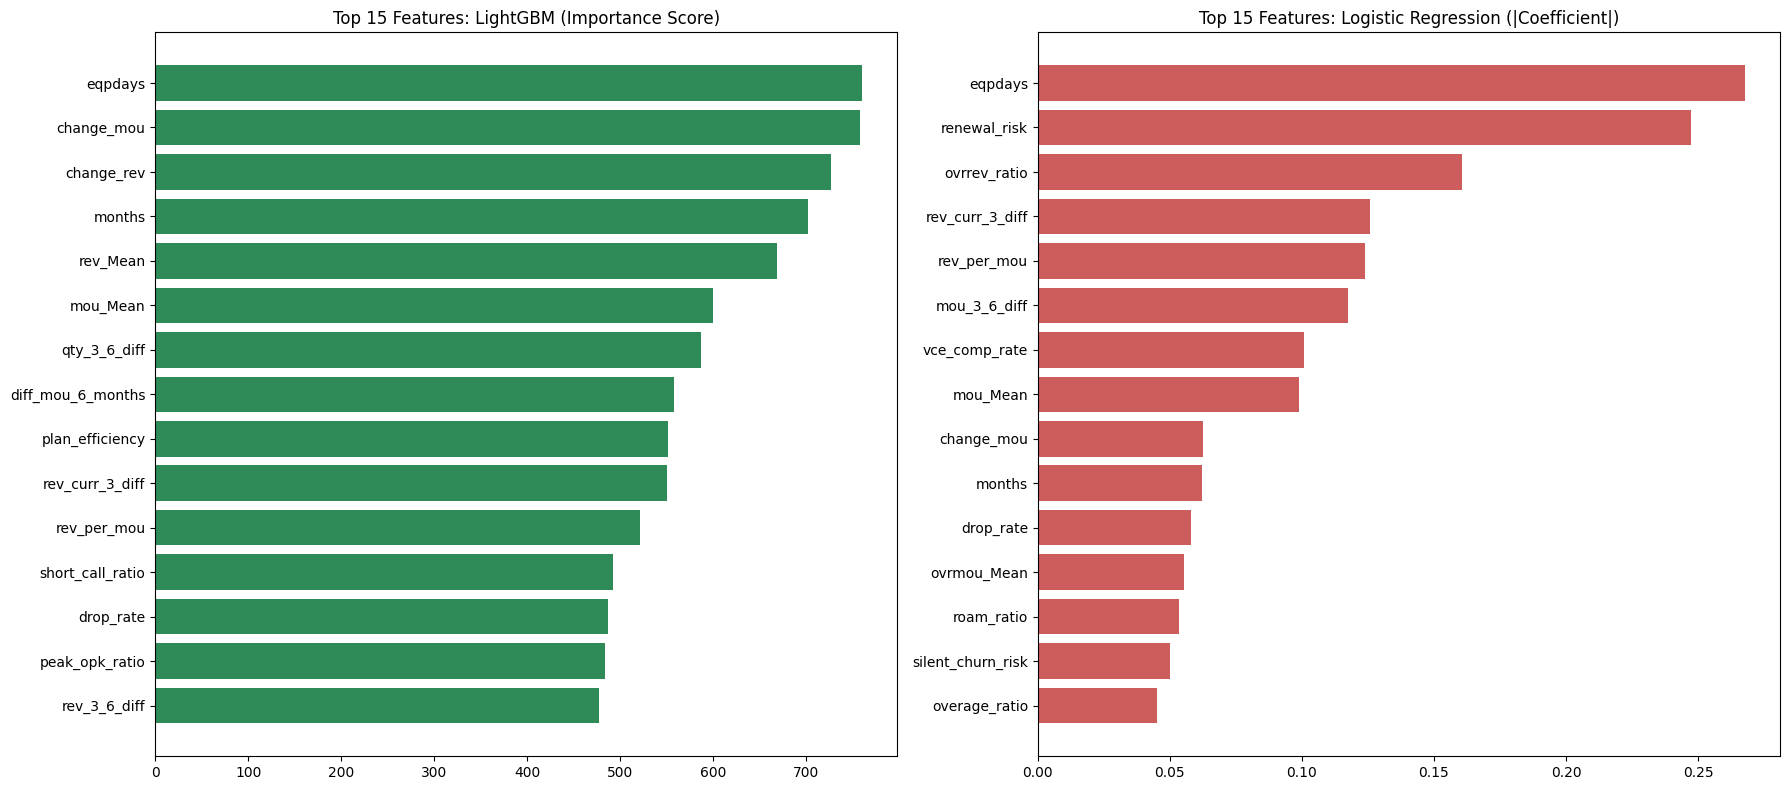

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ensure the mapping matches the actual number of coefficients
# The Logistic Regression model was trained on the scaled training set
# which corresponds to the columns in the X_train/updated_features list used at that time.

coef_len = len(log_reg_model.coef_[0])
features_to_use = updated_features[:coef_len]

# 1. Extract LightGBM Importance
lgb_importance = pd.DataFrame({
    'Feature': updated_features,
    'Importance': lgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False).head(15)

# 2. Extract Logistic Regression Coefficients
log_reg_coefs = pd.DataFrame({
    'Feature': features_to_use,
    'Absolute_Coefficient': np.abs(log_reg_model.coef_[0])
}).sort_values(by='Absolute_Coefficient', ascending=False).head(15)

# Plotting
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# LightGBM Plot
axes[0].barh(lgb_importance['Feature'], lgb_importance['Importance'], color='seagreen')
axes[0].set_title('Top 15 Features: LightGBM (Importance Score)')
axes[0].invert_yaxis()

# Logistic Regression Plot
axes[1].barh(log_reg_coefs['Feature'], log_reg_coefs['Absolute_Coefficient'], color='indianred')
axes[1].set_title('Top 15 Features: Logistic Regression (|Coefficient|)')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

***LightBGM model*** is preffered here due to
 and

*   better AUC score=**0.673**---
*   Great ROI - saves roughly ** $14.3 M **---

*   Net Gain = **$12.5 M** ----

 with a Threshold =0.35 --> **Recall=0.91 , Precision=0.55**